# Arquitectura de Agentes Inteligentes con LangGraph para Catálogos E-commerce

## Transformación Digital de Fichas de Producto mediante Grafos de Estado

En una startup de comercio electrónico, el procesamiento masivo de productos entrantes (onboarding de inventario) representa uno de los mayores cuellos de botella operacionales. Los proveedores entregan títulos ambiguos, descripciones escasas o inconsistentes y referencias a imágenes sin metadatos estructurados.

Un pipeline de automatización tradicional basado en reglas fijas o consultas aisladas a un modelo de lenguaje (LLM) no logra resolver la variabilidad de estos datos. La arquitectura basada en **Grafos de Estado con LangGraph** permite construir sistemas capaces de:

- **Mantener un estado mutable unificado:** Capturar y actualizar incrementalmente los campos del producto (título optimizado, descripción SEO, etiquetas de imágenes, categoría, especificaciones técnicas).
- **Ejecutar razonamiento condicional y dinámico:** Inspeccionar el grado de completitud de la ficha del producto y decidir iterativamente qué herramientas invocar (ej. extraer atributos visuales, consultar bases de datos de taxonomía, validar normativas comerciales).
- **Garantizar determinismo estructural:** A diferencia de marcos puramente autonómicos u orientados a roles sin restricciones, LangGraph permite fijar los caminos críticos mediante nodos y aristas explicitadas en código Python, asegurando que la calidad del catálogo cumpla con los estándares del canal de ventas antes de ser publicado.

## Anatomía de un Agente de Curaduría de Producto


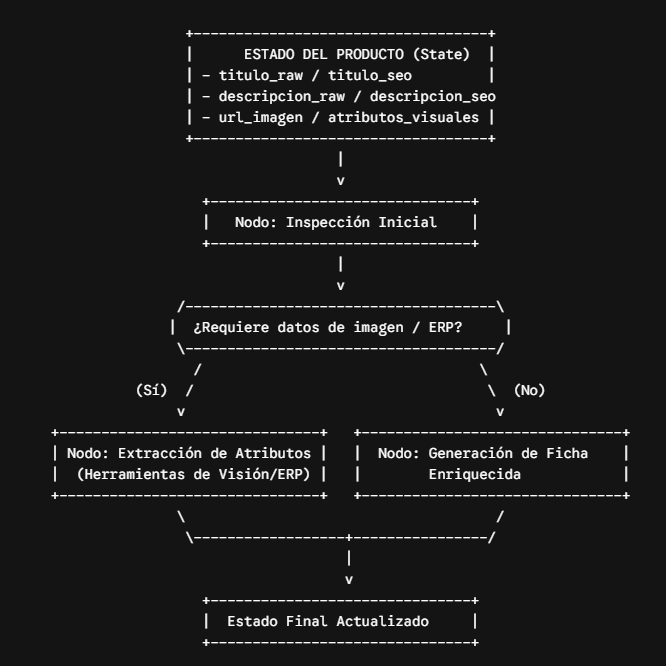

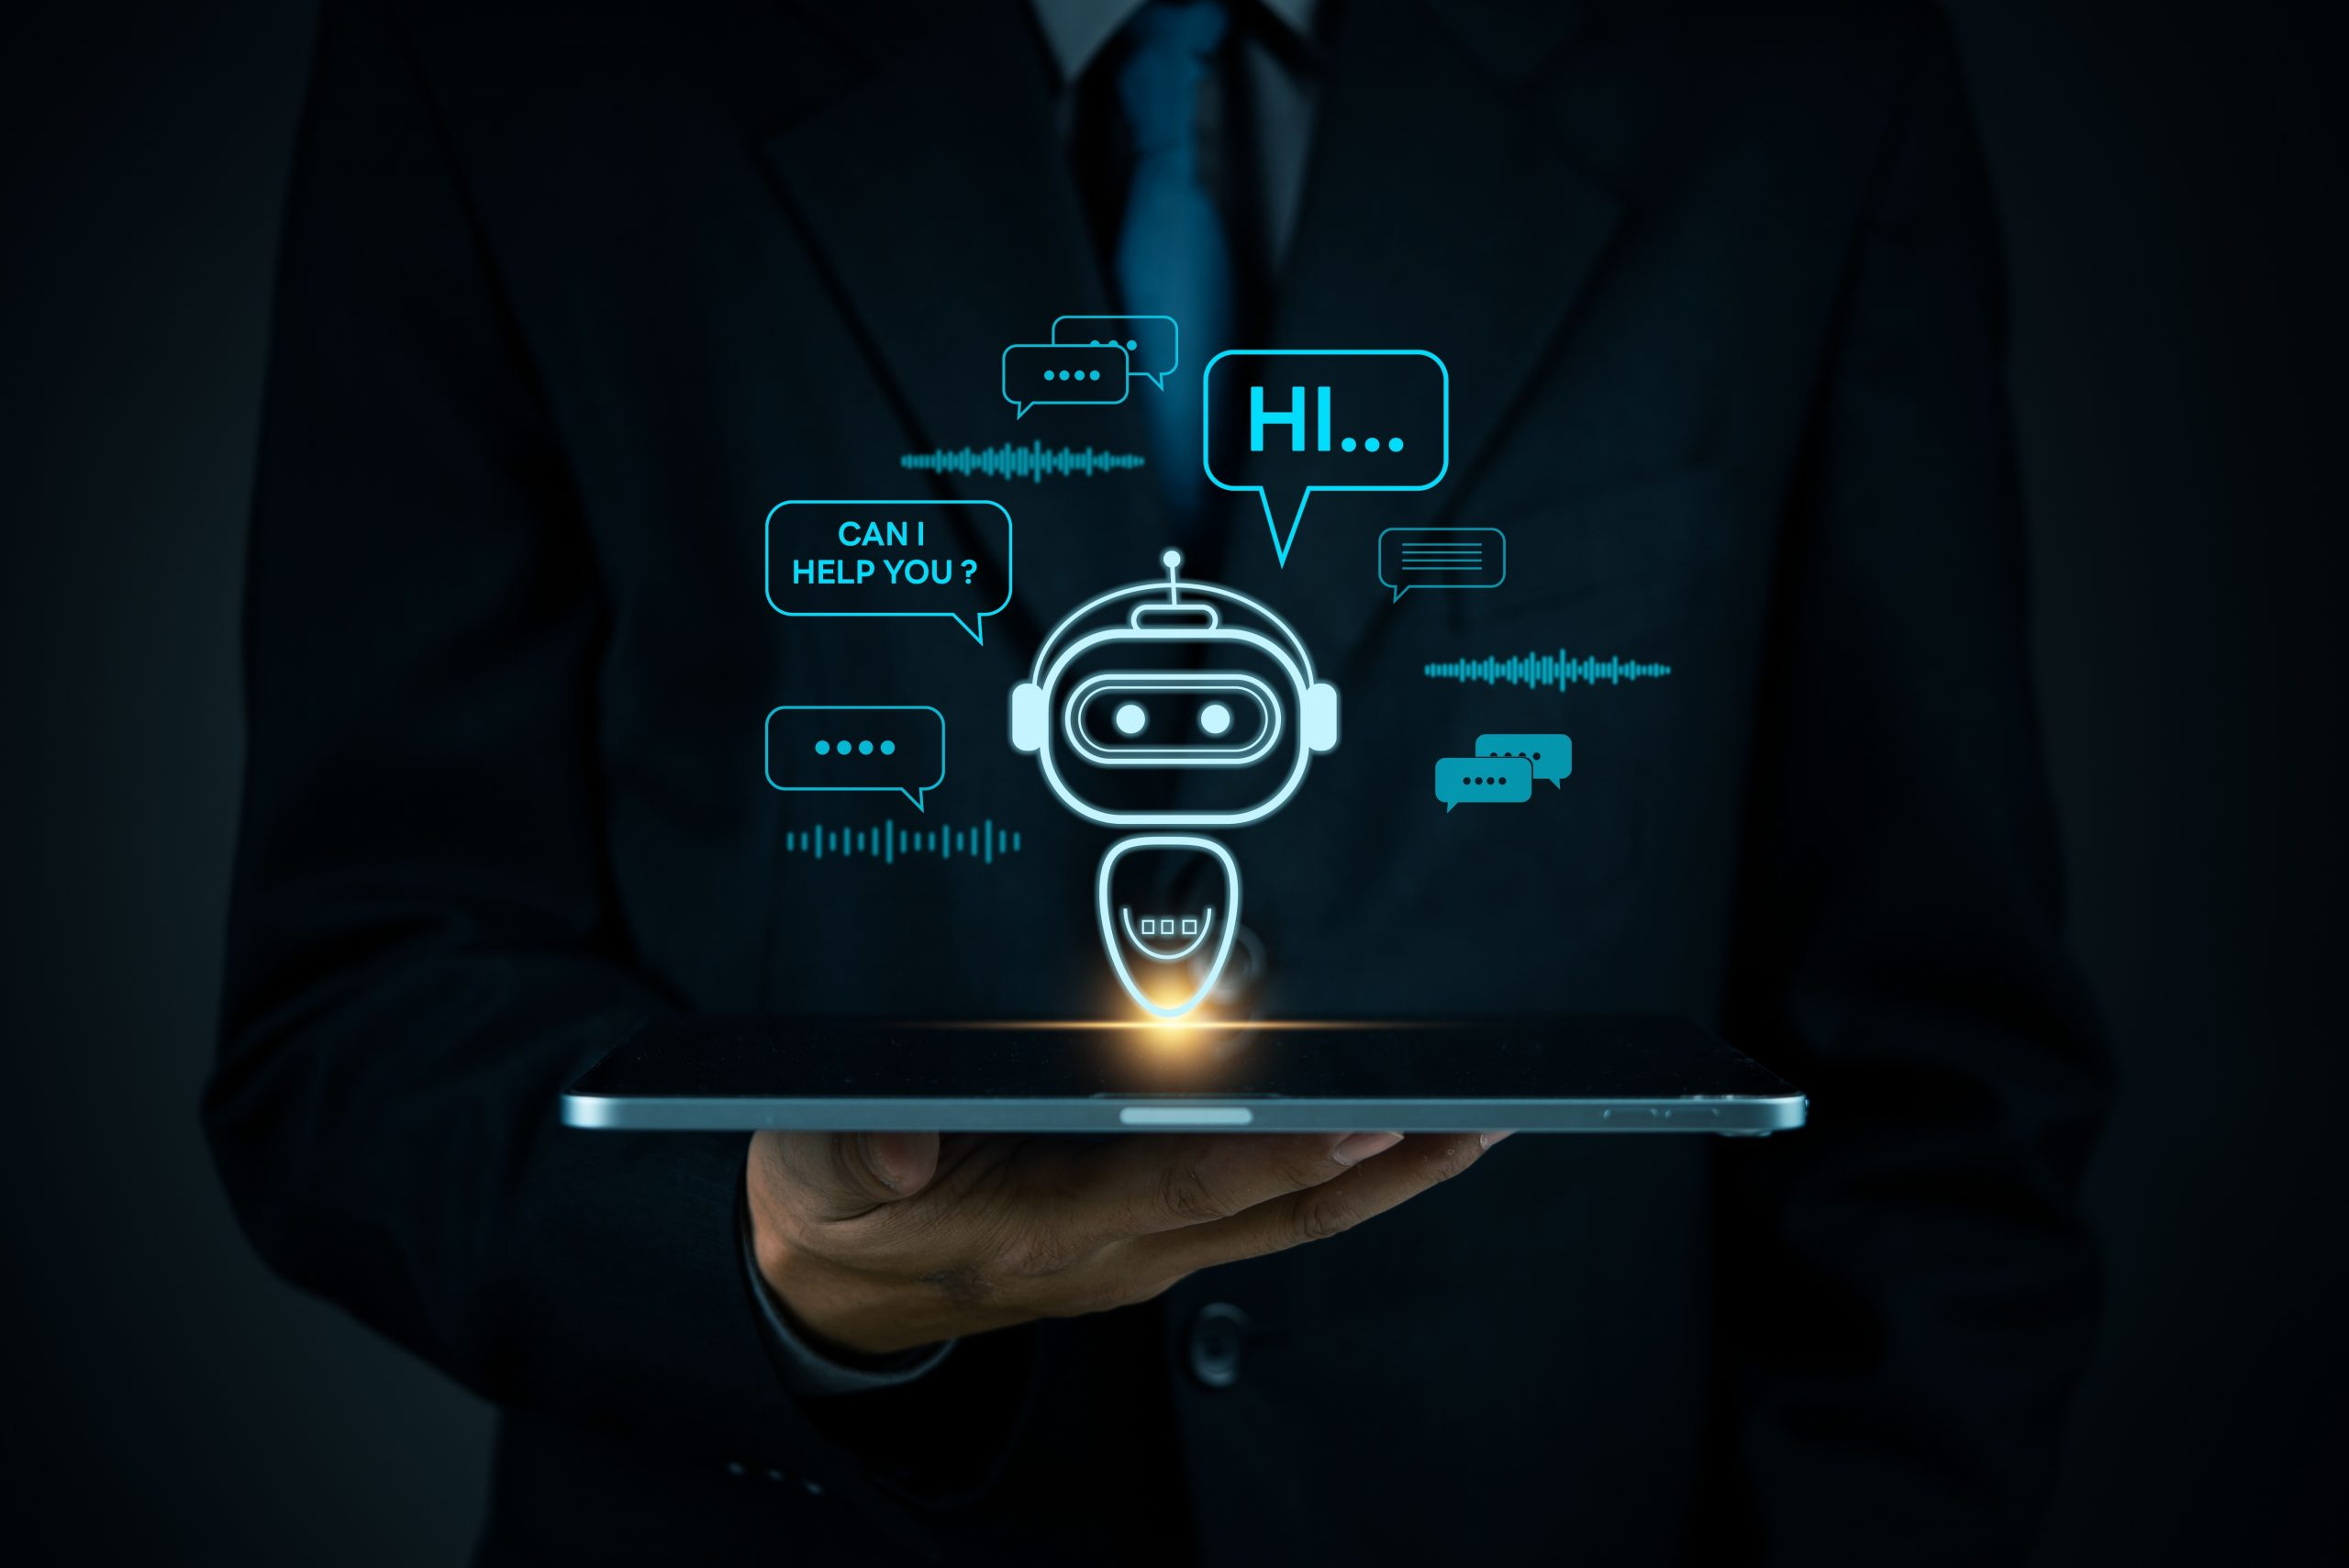


## Implementación Práctica

In [1]:
!pip install -qU langchain-google-genai langchain pydantic

In [2]:
import os
from pydantic import BaseModel, Field
from google.colab import userdata
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_core.messages import HumanMessage
from langgraph.graph import StateGraph, START, END


# =====================================================================
# 1. CONFIGURACIÓN DEL ENTORNO DE TRABAJO
# =====================================================================

def configurar_credenciales() -> bool:
    try:
        os.environ["GOOGLE_API_KEY"] = userdata.get('GOOGLE_API_KEY')
        print(" Credenciales de Google API configuradas exitosamente.")
        return True
    except Exception as error:
        print(f"X Error al cargar credenciales: {error}")
        return False


# =====================================================================
# 2. DEFINICIÓN DEL ESTADO CON PYDANTIC Y PYTHON MODERNO
# =====================================================================

class EstadoProducto(BaseModel):
    # Tipado moderno sin necesidad de importar desde 'typing'
    titulo_raw: str
    descripcion_raw: str
    url_imagen: str
    # Uso de pipe (|) para valores nulos introducido en Python 3.10
    atributos_extraidos: str | None = Field(default=None)
    titulo_seo: str | None = Field(default=None)
    descripcion_seo: str | None = Field(default=None)


# =====================================================================
# 3. HERRAMIENTAS Y SIMULADORES DE SERVICIOS EXTERNOS
# =====================================================================

def consultar_analisis_imagen_mock(url_imagen: str) -> str:
    # Uso de dict nativo en lugar de Dict de typing
    base_datos_imagenes: dict[str, str] = {
        "https://cdn.ecommerce.com/img001.jpg": "Color: Negro Mate | Material: Cuero Sintético | Estilo: Urbano",
        "https://cdn.ecommerce.com/img002.jpg": "Color: Azul Marino | Material: Algodón Orgánico | Talla: M"
    }
    return base_datos_imagenes.get(url_imagen, "Color: No identificado | Material: Estándar")


# =====================================================================
# 4. DEFINICIÓN DE NODOS DEL GRAFO
# =====================================================================

def nodo_analizar_imagen(estado: EstadoProducto) -> dict[str, str]:
    print(" [Nodo Visual]: Analizando atributos de la imagen del producto...")
    atributos = consultar_analisis_imagen_mock(estado.url_imagen)
    print(f"   Atributos detectados: {atributos}")
    # Retornamos un diccionario con el fragmento del estado a actualizar
    return {"atributos_extraidos": atributos}


def nodo_generar_ficha_seo(estado: EstadoProducto) -> dict[str, str]:
    print(" [Nodo Redactor SEO]: Creando título y descripción optimizados...")
    llm = ChatGoogleGenerativeAI(model="gemini-3.5-flash-lite")

    prompt = (
        "Eres un especialista en Copywriting y SEO para E-commerce.\n"
        f"Título Original: {estado.titulo_raw}\n"
        f"Descripción Original: {estado.descripcion_raw}\n"
        f"Atributos Visuales: {estado.atributos_extraidos}\n\n"
        "Genera un título optimizado para venta online (máximo 12 palabras) "
        "y una descripción atractiva que resalte los beneficios clave.\n"
        "Formato de respuesta estricto:\n"
        "TÍTULO: \n"
        "DESCRIPCIÓN: "
    )

    respuesta = llm.invoke([HumanMessage(content=prompt)])
    texto_respuesta = str(respuesta.content)

    nuevo_titulo = estado.titulo_raw
    nueva_descripcion = estado.descripcion_raw

    for linea in texto_respuesta.split("\n"):
        if linea.startswith("TÍTULO:"):
            nuevo_titulo = linea.replace("TÍTULO:", "").strip()
        elif linea.startswith("DESCRIPCIÓN:"):
            nueva_descripcion = linea.replace("DESCRIPCIÓN:", "").strip()

    return {
        "titulo_seo": nuevo_titulo,
        "descripcion_seo": nueva_descripcion
    }


# =====================================================================
# 5. COMPILACIÓN Y CONSTRUCCIÓN DEL GRAFO
# =====================================================================

def construir_grafo_ecommerce():
    builder = StateGraph(EstadoProducto)

    builder.add_node("analizar_imagen", nodo_analizar_imagen)
    builder.add_node("generar_ficha_seo", nodo_generar_ficha_seo)

    builder.add_edge(START, "analizar_imagen")
    builder.add_edge("analizar_imagen", "generar_ficha_seo")
    builder.add_edge("generar_ficha_seo", END)

    return builder.compile()


# =====================================================================
# 6. EJECUCIÓN DEL FLUJO DE OPTIMIZACIÓN
# =====================================================================

if __name__ == "__main__":
    if configurar_credenciales():
        agente_catalogacion = construir_grafo_ecommerce()

        # Instanciamos el estado inicial directamente como un objeto Pydantic
        producto_inicial = EstadoProducto(
            titulo_raw="zapatilla urbana negra",
            descripcion_raw="calzado para uso diario comodo",
            url_imagen="https://cdn.ecommerce.com/img001.jpg"
        )

        print("\n--- INICIANDO PROCESAMIENTO DE FICHA DE PRODUCTO ---")
        # Invocación del grafo; LangGraph gestiona la validación del esquema Pydantic internamente
        resultado = agente_catalogacion.invoke(producto_inicial)

        print("\n================ RESULTADO FINAL DEL CATÁLOGO ================")
        print(f" Título Optimizado SEO: {resultado['titulo_seo']}")
        print(f" Descripción Persuasiva: {resultado['descripcion_seo']}")
        print(f" Atributos Inspeccionados: {resultado['atributos_extraidos']}")
        print("==============================================================")

 Credenciales de Google API configuradas exitosamente.

--- INICIANDO PROCESAMIENTO DE FICHA DE PRODUCTO ---
 [Nodo Visual]: Analizando atributos de la imagen del producto...
   Atributos detectados: Color: Negro Mate | Material: Cuero Sintético | Estilo: Urbano
 [Nodo Redactor SEO]: Creando título y descripción optimizados...



================ RESULTADO FINAL DEL CATÁLOGO ================
 Título Optimizado SEO: zapatilla urbana negra
 Descripción Persuasiva: calzado para uso diario comodo
 Atributos Inspeccionados: Color: Negro Mate | Material: Cuero Sintético | Estilo: Urbano


## Modelado de Estado Compartido y Flujos Deterministas en Catálogos de Productos

En el procesamiento masivo de datos de e-commerce, el principal desafío técnico radica en la impredecibilidad de los insumos. Un catálogo proveniente de un nuevo proveedor puede contener registros completos con URLs de imágenes válidas, mientras que otros carecen de títulos entendibles o incluyen especificaciones en formatos no estructurados. Dejar la orquestación de estos flujos a la intuición libre de un modelo de lenguaje (LLM) genera fallas operacionales, costos innecesarios en tokens y fichas de producto defectuosas en el canal de ventas.

Para resolver esto, **LangGraph** introduce el concepto de **Estado Compartido (Shared State)** combinado con **Aristas Condicionales (Conditional Edges)**. Esta combinación permite que el sistema funcione como una máquina de estados finitos determinista donde los datos se validan, transforman y enrutan bajo reglas de negocio estrictas escritas en código Python nativo.

### 1. La Estructura del Estado Compartido (Shared State)

El estado central es la fuente única de verdad durante todo el ciclo de vida de procesamiento del producto. Al implementarlo mediante `BaseModel` de Pydantic en Python moderno, logramos tres objetivos críticos:

- **Validación estricta de esquemas:** Garantiza que ningún nodo retorne datos con tipos incorrectos o estructuras incompletas.
- **Inmutabilidad y trazabilidad:** Cada nodo recibe una snapshot del estado, calcula una transformación parcial y retorna únicamente los campos modificados.
- **Propagación de banderas de control (Flags):** Permite guardar estados lógicos (ej. `es_valido`, `requiere_analisis_imagen`) que sirven de insumo para las decisiones del enrutador.

### 2. Enrutamiento Determinista vs. Autonomía Estocástica

En lugar de delegar al modelo la decisión de qué hacer a continuación, el programador define funciones puras llamadas **Enrutadores (Routers)**. El enrutador examina el estado actual y retorna el nombre exacto del siguiente nodo al que debe saltar el flujo:

- Si el producto no cumple con los requisitos mínimos (ej. sin título o SKU), el enrutador lo desvía inmediatamente al **Nodo de Rechazo**, evitando gastar llamadas a APIs de visión o LLMs.
- Si el producto incluye una URL de imagen, el flujo se desvía al **Nodo de Análisis Visual** para enriquecer el contexto.
- Si la entrada es válida y cuenta con contexto suficiente, pasa directo al **Nodo Copywriter SEO**.

### Parte Práctica: Implementación de Flujo Determinista con Pydantic y LangGraph

In [3]:
import os
from pydantic import BaseModel, Field
from google.colab import userdata
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_core.messages import HumanMessage
from langgraph.graph import StateGraph, START, END


# =====================================================================
# 1. CONFIGURACIÓN DE CREDENCIALES DEL ENTORNO
# =====================================================================

def inicializar_entorno() -> bool:
    # Extrae la API Key configurada en los secretos del entorno Colab
    try:
        os.environ["GOOGLE_API_KEY"] = userdata.get('GOOGLE_API_KEY')
        print(" Credenciales cargadas exitosamente.")
        return True
    except Exception as error:
        print(f"X Error al cargar las credenciales: {error}")
        return False


# =====================================================================
# 2. MODELADO DEL ESTADO COMPARTIDO CON PYDANTIC MODERNO (SIN TYPING)
# =====================================================================

class EstadoCatalogo(BaseModel):
    # Identificador único del producto en la base de datos ERP/E-commerce
    sku: str
    # Datos crudos ingresados por el proveedor
    titulo_raw: str
    descripcion_raw: str
    # Uso exclusivo del operador pipe (|) nativo de Python 3.10+
    url_imagen: str | None = Field(default=None)

    # Banderas de control de flujo determinista
    es_valido: bool = Field(default=True)
    motivo_rechazo: str | None = Field(default=None)
    requiere_analisis_imagen: bool = Field(default=False)

    # Atributos incrementales generados por los nodos
    atributos_imagen: str | None = Field(default=None)
    titulo_optimizado: str | None = Field(default=None)
    descripcion_optimizada: str | None = Field(default=None)


# =====================================================================
# 3. DEFINICIÓN DE NODOS DE PROCESAMIENTO
# =====================================================================

def nodo_validar_entrada(estado: EstadoCatalogo) -> dict[str, str | bool]:
    # Analiza la calidad inicial de los datos recibidos del producto
    print(f" [Nodo Validación]: Inspeccionando SKU {estado.sku}...")

    # Regla de negocio 1: El título debe tener al menos 3 caracteres
    if not estado.titulo_raw or len(estado.titulo_raw.strip()) < 3:
        print("   X Rechazado: Título demasiado corto o inexistente.")
        return {
            "es_valido": False,
            "motivo_rechazo": "El título del producto es inválido o está vacío."
        }

    # Regla de negocio 2: Determinar si existe imagen válida para procesar
    tiene_imagen = bool(estado.url_imagen and estado.url_imagen.startswith("http"))
    print(f"   Validación exitosa. ¿Requiere análisis visual?: {tiene_imagen}")

    # Actualiza las banderas en el estado compartido mediante dict nativo
    return {
        "es_valido": True,
        "requiere_analisis_imagen": tiene_imagen
    }


def nodo_analizar_imagen(estado: EstadoCatalogo) -> dict[str, str]:
    # Simulador de extracción de atributos mediante modelos de visión multimodales
    print(" [Nodo Visión]: Extrayendo características visuales de la imagen...")

    # Simulación de respuesta de visión por ordenador
    atributos_detectados = "Color: Rojo Vivo | Material: Poliéster Deportivo | Acabado: Brillante"
    print(f"   Atributos extraídos: {atributos_detectados}")

    # Retorna los atributos para nutrir el estado
    return {"atributos_imagen": atributos_detectados}


def nodo_generar_copywriting(estado: EstadoCatalogo) -> dict[str, str]:
    # Genera el contenido enriquecido utilizando Gemini
    print(" [Nodo Copywriter]: Redactando título y descripción profesional...")
    llm = ChatGoogleGenerativeAI(model="gemini-3.5-flash-lite")

    # Construye el contexto acumulando los datos disponibles en el estado
    contexto_atributos = estado.atributos_imagen if estado.atributos_imagen else "Sin atributos visuales extras"

    prompt = (
        "Eres un experto en Marketing Digital y E-commerce.\n"
        f"SKU: {estado.sku}\n"
        f"Título Original: {estado.titulo_raw}\n"
        f"Descripción Original: {estado.descripcion_raw}\n"
        f"Atributos Extraídos: {contexto_atributos}\n\n"
        "Crea una ficha optimizada para la tienda online.\n"
        "Responde exactamente con el siguiente formato:\n"
        "TÍTULO: \n"
        "DESCRIPCIÓN: "
    )

    respuesta = llm.invoke([HumanMessage(content=prompt)])
    texto = str(respuesta.content)

    # Extracción de las secciones de la respuesta
    nuevo_titulo = estado.titulo_raw
    nueva_descripcion = estado.descripcion_raw

    for linea in texto.split("\n"):
        if linea.startswith("TÍTULO:"):
            nuevo_titulo = linea.replace("TÍTULO:", "").strip()
        elif linea.startswith("DESCRIPCIÓN:"):
            nueva_descripcion = linea.replace("DESCRIPCIÓN:", "").strip()

    return {
        "titulo_optimizado": nuevo_titulo,
        "descripcion_optimizada": nueva_descripcion
    }


def nodo_registrar_rechazo(estado: EstadoCatalogo) -> dict[str, str]:
    # Maneja de forma limpia los registros que fallaron las reglas de negocio
    print(f" [Nodo Rechazo]: Registrando motivo de fallo para SKU {estado.sku}...")
    mensaje_error = f"PRODUCTO BLOQUEADO: {estado.motivo_rechazo}"
    return {
        "titulo_optimizado": "RECHAZADO",
        "descripcion_optimizada": mensaje_error
    }


# =====================================================================
# 4. ENRUTADOR CONDICIONAL DETERMINISTA
# =====================================================================

def enrutador_control_calidad(estado: EstadoCatalogo) -> str:
    # Función pura de bifurcación que retorna directamente cadenas de texto nativas
    if not estado.es_valido:
        # Si el producto fue marcado como inválido, desviarlo a rechazo
        print(" [Enrutador]: Redirigiendo a -> nodo_registrar_rechazo")
        return "nodo_registrar_rechazo"

    if estado.requiere_analisis_imagen:
        # Si requiere visión por ordenador, ir al nodo de imagen
        print(" [Enrutador]: Redirigiendo a -> nodo_analizar_imagen")
        return "nodo_analizar_imagen"

    # En caso contrario, avanzar directamente a la redacción
    print(" [Enrutador]: Redirigiendo a -> nodo_generar_copywriting")
    return "nodo_generar_copywriting"


# =====================================================================
# 5. COMPILACIÓN DE LA TOPOLOGÍA DEL GRAFO
# =====================================================================

def construir_grafo_catalogacion_determinista():
    # Inicializa el grafo indicando el modelo de estado Pydantic
    builder = StateGraph(EstadoCatalogo)

    # Registra los cuatro nodos operacionales
    builder.add_node("nodo_validar_entrada", nodo_validar_entrada)
    builder.add_node("nodo_analizar_imagen", nodo_analizar_imagen)
    builder.add_node("nodo_generar_copywriting", nodo_generar_copywriting)
    builder.add_node("nodo_registrar_rechazo", nodo_registrar_rechazo)

    # Arista inicial fija hacia la validación
    builder.add_edge(START, "nodo_validar_entrada")

    # Arista condicional: evalúa la salida de validación y elige el siguiente paso
    builder.add_conditional_edges(
        "nodo_validar_entrada",
        enrutador_control_calidad,
        {
            "nodo_registrar_rechazo": "nodo_registrar_rechazo",
            "nodo_analizar_imagen": "nodo_analizar_imagen",
            "nodo_generar_copywriting": "nodo_generar_copywriting"
        }
    )

    # Secuencias finales tras procesar las imágenes o rechazar
    builder.add_edge("nodo_analizar_imagen", "nodo_generar_copywriting")
    builder.add_edge("nodo_generar_copywriting", END)
    builder.add_edge("nodo_registrar_rechazo", END)

    # Compila el grafo de ejecución
    return builder.compile()


# =====================================================================
# 6. EJECUCIÓN Y CASOS DE PRUEBA
# =====================================================================

if __name__ == "__main__":
    if inicializar_entorno():
        grafo = construir_grafo_catalogacion_determinista()

        # CASO 1: Producto válido con imagen que requiere análisis completo
        print("\n================ EVALUANDO CASO 1: PRODUCTO VÁLIDO CON IMAGEN ================")
        prod_valido = EstadoCatalogo(
            sku="SKU-8899",
            titulo_raw="polera deportiva runner",
            descripcion_raw="polera respirable para correr maratones",
            url_imagen="https://cdn.ecommerce.com/polera.jpg"
        )
        res_1 = grafo.invoke(prod_valido)
        print(f"Resultado Título: {res_1['titulo_optimizado']}")
        print(f"Resultado Descripción: {res_1['descripcion_optimizada']}")

        # CASO 2: Producto defectuoso sin título suficiente
        print("\n================ EVALUANDO CASO 2: PRODUCTO INVÁLIDO ================")
        prod_invalido = EstadoCatalogo(
            sku="SKU-0012",
            titulo_raw="a",  # Título inválido por longitud
            descripcion_raw="sin datos",
            url_imagen=None
        )
        res_2 = grafo.invoke(prod_invalido)
        print(f"Resultado Título: {res_2['titulo_optimizado']}")
        print(f"Resultado Descripción: {res_2['descripcion_optimizada']}")

 Credenciales cargadas exitosamente.

================ EVALUANDO CASO 1: PRODUCTO VÁLIDO CON IMAGEN ================
 [Nodo Validación]: Inspeccionando SKU SKU-8899...
   Validación exitosa. ¿Requiere análisis visual?: True
 [Enrutador]: Redirigiendo a -> nodo_analizar_imagen
 [Nodo Visión]: Extrayendo características visuales de la imagen...
   Atributos extraídos: Color: Rojo Vivo | Material: Poliéster Deportivo | Acabado: Brillante
 [Nodo Copywriter]: Redactando título y descripción profesional...
Resultado Título: polera deportiva runner
Resultado Descripción: polera respirable para correr maratones

================ EVALUANDO CASO 2: PRODUCTO INVÁLIDO ================
 [Nodo Validación]: Inspeccionando SKU SKU-0012...
   X Rechazado: Título demasiado corto o inexistente.
 [Enrutador]: Redirigiendo a -> nodo_registrar_rechazo
 [Nodo Rechazo]: Registrando motivo de fallo para SKU SKU-0012...
Resultado Título: RECHAZADO
Resultado Descripción: PRODUCTO BLOQUEADO: El título del product

## Construcción de Grafos Cíclicos y Control Fino para la Optimización de Fichas de Producto

En las arquitecturas de software tradicionales basadas en grafos acíclicos dirigidos (DAGs), los datos fluyen en una única dirección. Sin embargo, en la generación de contenido mediante Modelos de Lenguaje, la primera salida no siempre cumple con las directrices de la marca o las reglas de negocio.

Para construir verdaderos agentes autónomos, es fundamental implementar **Grafos Cíclicos**. LangGraph permite que el flujo retroceda a un nodo anterior basándose en el análisis del estado actual, creando un **Bucle de Evaluación (QA Loop)**.

Para que un ciclo sea seguro y controlable en producción, requiere dos componentes estructurales en el estado:

1. **Un registro de retroalimentación (Feedback):** Un campo que almacene los motivos exactos del rechazo para que el nodo generador corrija sus errores en la siguiente iteración.
2. **Un límite estricto de iteraciones (Time-to-Live / Counter):** Un contador numérico para evitar bucles infinitos en caso de que el LLM sea incapaz de resolver el problema.

### Implementación del Bucle de Calidad (QA Loop) con Pydantic

El siguiente código implementa un flujo donde un **Generador** redacta la ficha, y un **Revisor** (actuando como motor de reglas determinista) evalúa si el texto contiene palabras prohibidas por el manual de marca (ej. "barato", "imitación"). Si falla, el grafo entra en un ciclo de corrección hasta que se aprueba o se alcanza el límite de intentos.

In [4]:
import os
from pydantic import BaseModel, Field
from google.colab import userdata
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_core.messages import HumanMessage
from langgraph.graph import StateGraph, START, END

# =====================================================================
# 1. CONFIGURACIÓN DEL ENTORNO
# =====================================================================

def inicializar_entorno() -> bool:
    try:
        os.environ["GOOGLE_API_KEY"] = userdata.get('GOOGLE_API_KEY')
        return True
    except Exception as error:
        print(f"X Error al cargar credenciales: {error}")
        return False

# =====================================================================
# 2. DEFINICIÓN DEL ESTADO CON CONTROL DE CICLOS (SIN TYPING LEGACY)
# =====================================================================

class EstadoOptimizado(BaseModel):
    # Datos de entrada
    sku: str
    titulo_raw: str
    descripcion_raw: str

    # Datos generados
    texto_comercial: str | None = Field(default=None)

    # Variables de control cíclico
    intentos_edicion: int = Field(default=0)
    estado_aprobado: bool = Field(default=False)
    feedback_revisor: str | None = Field(default=None)

# =====================================================================
# 3. NODOS DE GENERACIÓN Y REVISIÓN (ACTORES DEL CICLO)
# =====================================================================

def nodo_redactor_seo(estado: EstadoOptimizado) -> dict[str, str | int]:
    print(f"\n [Redactor] Iteración {estado.intentos_edicion + 1}: Generando copy para {estado.sku}")
    llm = ChatGoogleGenerativeAI(model="gemini-3.5-flash-lite", temperature=0.7)

    # Construcción dinámica del prompt basada en intentos previos
    instrucciones_base = (
        "Eres un copywriter de E-commerce. Combina el título y la descripción en "
        "un solo párrafo comercial y persuasivo de máximo 40 palabras.\n"
        f"Datos originales: {estado.titulo_raw} - {estado.descripcion_raw}\n"
    )

    # Si existe feedback previo por un rechazo, inyectarlo como corrección prioritaria
    if estado.feedback_revisor:
        print(f"   -> Aplicando correcciones solicitadas: {estado.feedback_revisor}")
        instrucciones_base += f"\nATENCIÓN - CORRECCIÓN REQUERIDA: {estado.feedback_revisor}\n"

    respuesta = llm.invoke([HumanMessage(content=instrucciones_base)])
    nuevo_texto = str(respuesta.content).strip()

    # Se actualiza el texto y se incrementa el contador del bucle
    return {
        "texto_comercial": nuevo_texto,
        "intentos_edicion": estado.intentos_edicion + 1
    }

def nodo_auditor_marca(estado: EstadoOptimizado) -> dict[str, bool | str | None]:
    print(" [Auditor] Revisando cumplimiento de manual de marca y SEO...")
    texto_actual = str(estado.texto_comercial).lower()

    # Regla 1: Palabras prohibidas que devalúan la marca
    palabras_prohibidas = ["barato", "barata", "imitación", "fake", "ganga"]
    infracciones = [palabra for palabra in palabras_prohibidas if palabra in texto_actual]

    if infracciones:
        motivo = f"El texto contiene palabras prohibidas por la marca: {', '.join(infracciones)}. Usa sinónimos premium como 'accesible' o 'excelente valor'."
        print(f"   X Rechazado: {motivo}")
        return {
            "estado_aprobado": False,
            "feedback_revisor": motivo
        }

    # Regla 2: Restricción de longitud (ej. meta-descripción demasiado larga)
    palabras_totales = len(texto_actual.split())
    if palabras_totales > 45:
        motivo = f"El texto es demasiado largo ({palabras_totales} palabras). Debe ser inferior a 45 palabras."
        print(f"   X Rechazado: {motivo}")
        return {
            "estado_aprobado": False,
            "feedback_revisor": motivo
        }

    # Si supera todas las pruebas, se aprueba y se limpia el feedback
    print("   ✓ Aprobado: El contenido cumple con las directrices.")
    return {
        "estado_aprobado": True,
        "feedback_revisor": None
    }

# =====================================================================
# 4. ENRUTADOR DEL CICLO (CONDITIONAL EDGE)
# =====================================================================

def evaluar_ciclo(estado: EstadoOptimizado) -> str:
    # Lógica de salida de emergencia (cortocircuito)
    if estado.estado_aprobado:
        print(" [Enrutador]: Producto aprobado. Finalizando flujo -> END")
        return "END"

    # Límite de seguridad: máximo 3 intentos para no agotar tokens en bucles infinitos
    if estado.intentos_edicion >= 3:
        print(" [Enrutador]: Máximo de intentos alcanzado. Forzando salida -> END")
        return "END"

    # Si no está aprobado y quedan intentos, retroceder al nodo redactor
    print(" [Enrutador]: Devolviendo a redacción -> nodo_redactor_seo")
    return "nodo_redactor_seo"

# =====================================================================
# 5. COMPILACIÓN DEL GRAFO CÍCLICO
# =====================================================================

def construir_grafo_ciclico():
    builder = StateGraph(EstadoOptimizado)

    # Agregar nodos
    builder.add_node("nodo_redactor_seo", nodo_redactor_seo)
    builder.add_node("nodo_auditor_marca", nodo_auditor_marca)

    # Flujo secuencial principal
    builder.add_edge(START, "nodo_redactor_seo")
    builder.add_edge("nodo_redactor_seo", "nodo_auditor_marca")

    # Flujo condicional (El Ciclo)
    builder.add_conditional_edges(
        "nodo_auditor_marca",
        evaluar_ciclo,
        {
            "nodo_redactor_seo": "nodo_redactor_seo",
            "END": END
        }
    )

    return builder.compile()

# =====================================================================
# 6. EJECUCIÓN DEL BUCLE DE CONTROL
# =====================================================================

if __name__ == "__main__":
    if inicializar_entorno():
        grafo = construir_grafo_ciclico()

        # Producto problemático intencional: inducimos el uso de la palabra prohibida "barato"
        producto_prueba = EstadoOptimizado(
            sku="SKU-9901",
            titulo_raw="Smartwatch barato",
            descripcion_raw="Reloj inteligente muy barato y económico, es como una ganga."
        )

        print("\n--- INICIANDO PROCESAMIENTO CÍCLICO DE FICHA ---")
        resultado = grafo.invoke(producto_prueba)

        print("\n================ RESULTADO FINAL ==================")
        print(f" Intentos requeridos: {resultado['intentos_edicion']}")
        print(f" Aprobado por Auditoría: {resultado['estado_aprobado']}")
        print(f" Texto Final:\n {resultado['texto_comercial']}")
        if not resultado['estado_aprobado']:
             print(f" Razón final de fallo: {resultado['feedback_revisor']}")
        print("===================================================")


--- INICIANDO PROCESAMIENTO CÍCLICO DE FICHA ---

 [Redactor] Iteración 1: Generando copy para SKU-9901


/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:3908: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


 [Auditor] Revisando cumplimiento de manual de marca y SEO...
   X Rechazado: El texto contiene palabras prohibidas por la marca: ganga. Usa sinónimos premium como 'accesible' o 'excelente valor'.
 [Enrutador]: Devolviendo a redacción -> nodo_redactor_seo

 [Redactor] Iteración 2: Generando copy para SKU-9901
   -> Aplicando correcciones solicitadas: El texto contiene palabras prohibidas por la marca: ganga. Usa sinónimos premium como 'accesible' o 'excelente valor'.


/usr/local/lib/python3.13/dist-packages/langchain_google_genai/chat_models.py:3908: UserWarning: Model 'gemini-3.5-flash-lite' uses fixed sampling defaults; the sampling parameter(s) temperature will be ignored.
  request = self._build_request_config(


 [Auditor] Revisando cumplimiento de manual de marca y SEO...
   ✓ Aprobado: El contenido cumple con las directrices.
 [Enrutador]: Producto aprobado. Finalizando flujo -> END

================ RESULTADO FINAL ==================
 Intentos requeridos: 2
 Aprobado por Auditoría: True
 Texto Final:
 [{'type': 'text', 'text': 'Disfruta de la última tecnología en tu muñeca con este smartwatch accesible; un reloj inteligente de excelente valor que combina diseño, funcionalidad y un precio increíble para mantenerte conectado sin gastar de más.', 'extras': {'signature': 'EmAKXgFpFH0TlLuIyGPR2crjxUm9IwO6sx0desNZ47MylieCUjys8CEZ0qQuO3DEqO5nm/YgVKVRdxWrlJjjhk779Ca8DxZsDWMFdGlV2uUlnBbR9d3v6N5qJhaJqbEd618='}}]


## Herramientas Personalizadas y RAG Multimodal para Análisis de Imágenes y Fichas Técnicas

Hasta ahora hemos simulado el análisis de imágenes con diccionarios estáticos. En un e-commerce real, los agentes deben interactuar con el mundo exterior. Esto se logra combinando **Modelos Multimodales** (capaces de "ver" imágenes reales) y **Tool Calling** (herramientas que permiten al LLM consultar bases de datos, APIs de inventario o manuales PDF).

El uso de **RAG Multimodal (Retrieval-Augmented Generation)** permite al agente extraer el texto crudo del proveedor y cruzarlo simultáneamente con lo que observa en la fotografía del producto y lo que extrae de la base de datos de la empresa mediante herramientas.

### Implementación: Agente Multimodal con Tool Calling nativo

En este código, el agente recibe la URL de una imagen real. Utilizaremos el soporte multimodal de Gemini para analizar la imagen y una herramienta (decorador `@tool`) para simular la búsqueda de normativas de tallaje en la base de datos interna.

In [6]:
import os
import httpx
import base64
from pydantic import BaseModel, Field
from google.colab import userdata
from langchain_core.tools import tool
from langchain_core.messages import HumanMessage
from langchain_google_genai import ChatGoogleGenerativeAI
from langgraph.graph import StateGraph, START, END

# =====================================================================
# 1. CONFIGURACIÓN DEL ENTORNO
# =====================================================================

def inicializar_entorno() -> bool:
    try:
        os.environ["GOOGLE_API_KEY"] = userdata.get('GOOGLE_API_KEY')
        return True
    except Exception as error:
        print(f"X Error al cargar credenciales: {error}")
        return False

# =====================================================================
# 2. DEFINICIÓN DEL ESTADO COMPARTIDO (MODERNO)
# =====================================================================

class EstadoMultimodal(BaseModel):
    sku: str
    url_imagen: str
    categoria_base: str

    # Datos extraídos por el agente a través de visión y herramientas
    analisis_visual: str | None = Field(default=None)
    datos_tecnicos_externos: str | None = Field(default=None)
    ficha_final: str | None = Field(default=None)

# =====================================================================
# 3. CREACIÓN DE HERRAMIENTAS PERSONALIZADAS (TOOL CALLING)
# =====================================================================

@tool
def consultar_guia_tallas_interna(categoria: str) -> str:
    """
    Consulta la base de datos interna (RAG) para obtener las dimensiones
    exactas y normativas según la categoría del producto.
    """
    print(f"   [Tool Exec] Buscando guía de tallas en RAG para: {categoria}")
    base_datos_rag: dict[str, str] = {
        "calzado_deportivo": "Normativa: Las tallas deben mostrarse en US y EU. Material de suela recomendado para running: EVA o Caucho.",
        "vestuario_exterior": "Normativa: Indicar medidas de pecho y largo en cm. Advertir si el tallaje es ajustado (Slim Fit)."
    }
    return base_datos_rag.get(categoria, "Sin normativa técnica registrada para esta categoría.")

# =====================================================================
# 4. NODOS DE PROCESAMIENTO MULTIMODAL Y GENERACIÓN
# =====================================================================

def nodo_vision_y_herramientas(estado: EstadoMultimodal) -> dict[str, str]:
    print(f"\n [Nodo Multimodal]: Analizando visualmente el SKU {estado.sku} y consultando RAG...")

    # 4.1. Preparar la imagen descargándola en memoria
    # En producción se manejarían excepciones de red, aquí simplificamos
    respuesta_img = httpx.get(estado.url_imagen)
    imagen_base64 = base64.b64encode(respuesta_img.content).decode("utf-8")

    # 4.2. Ejecutar herramienta RAG de forma explícita o vinculada al LLM
    # Para este ejemplo estructurado, la herramienta se invoca directamente con la categoría
    datos_rag = consultar_guia_tallas_interna.invoke({"categoria": estado.categoria_base})

    # 4.3. Configurar Gemini con capacidades multimodales
    llm = ChatGoogleGenerativeAI(model="gemini-3.5-flash-lite")

    # 4.4. Crear el prompt estructurado combinando texto e imagen
    mensaje = HumanMessage(
        content=[
            {"type": "text", "text": "Describe detalladamente este producto basándote en la imagen. Enfócate en color, texturas, cierres, cordones y detalles de diseño que no son obvios en el título."},
            {"type": "image_url", "image_url": {"url": f"data:image/jpeg;base64,{imagen_base64}"}},
        ]
    )

    respuesta_vision = llm.invoke([mensaje])

    return {
        "analisis_visual": str(respuesta_vision.content),
        "datos_tecnicos_externos": datos_rag
    }

def nodo_redactor_integral(estado: EstadoMultimodal) -> dict[str, str]:
    print(" [Nodo Redactor]: Integrando visión, normativas RAG y estructura SEO...")
    llm = ChatGoogleGenerativeAI(model="gemini-3.5-flash-lite")

    prompt = (
        "Eres un Content Manager de un marketplace.\n"
        "Crea una ficha técnica completa combinando estrictamente esta información:\n\n"
        f"1. Lo que viste en la imagen:\n{estado.analisis_visual}\n"
        f"2. Las normativas y guías técnicas de la empresa (RAG):\n{estado.datos_tecnicos_externos}\n\n"
        "Redacta un párrafo descriptivo y luego una lista de 3 viñetas técnicas."
    )

    respuesta = llm.invoke([HumanMessage(content=prompt)])

    return {"ficha_final": str(respuesta.content)}

# =====================================================================
# 5. CONSTRUCCIÓN DEL GRAFO LINEAL
# =====================================================================

def construir_grafo_multimodal():
    builder = StateGraph(EstadoMultimodal)

    builder.add_node("nodo_vision_y_herramientas", nodo_vision_y_herramientas)
    builder.add_node("nodo_redactor_integral", nodo_redactor_integral)

    builder.add_edge(START, "nodo_vision_y_herramientas")
    builder.add_edge("nodo_vision_y_herramientas", "nodo_redactor_integral")
    builder.add_edge("nodo_redactor_integral", END)

    return builder.compile()

# =====================================================================
# 6. EJECUCIÓN DEL FLUJO MULTIMODAL
# =====================================================================

if __name__ == "__main__":
    if inicializar_entorno():
        agente_multimodal = construir_grafo_multimodal()

        # Usamos una imagen real pública de muestra (un zapato)
        producto_demo = EstadoMultimodal(
            sku="SKU-ZAP-001",
            categoria_base="calzado_deportivo",
            url_imagen="https://images.unsplash.com/photo-1542291026-7eec264c27ff?ixlib=rb-4.0.3&w=400&q=80"
        )

        print("\n--- INICIANDO ENRIQUECIMIENTO MULTIMODAL ---")
        resultado = agente_multimodal.invoke(producto_demo)

        print("\n================ RESULTADO FINAL ==================")
        print(f" Análisis Visual del Agente:\n {resultado['analisis_visual']}\n")
        print(f" Ficha Final Lista para E-commerce:\n {resultado['ficha_final']}")
        print("===================================================")


--- INICIANDO ENRIQUECIMIENTO MULTIMODAL ---

 [Nodo Multimodal]: Analizando visualmente el SKU SKU-ZAP-001 y consultando RAG...
   [Tool Exec] Buscando guía de tallas en RAG para: calzado_deportivo
 [Nodo Redactor]: Integrando visión, normativas RAG y estructura SEO...

================ RESULTADO FINAL ==================
 Análisis Visual del Agente:
 [{'type': 'text', 'text': 'Una foto de primer plano muestra un zapato Nike Free Flyknit rojo oscuro en un fondo rojo brillante.\n\nEl zapato Nike Free Flyknit tiene una parte superior textil con textura de punto. Es rojo oscuro en la puntera, con un tono rojo más brillante a medida que se desplaza hacia el medio pie y el talón. La marca Nike es un logotipo de diseño Nike blanco. El talón tiene un logotipo de diseño de Nike blanco.\n\nLos cordones son del mismo color que la puntera y el medio pie del zapato. La suela es blanca, hecha de espuma, con ranuras a lo largo del zapato. La lengüeta es de color rojo oscuro, con el logotipo "NIKE" 

# Arquitecturas Multi-Agente y Patrón Supervisor para Curaduría Completa de Productos

## Orquestación Jerárquica de Especialistas en Catálogos Complejos

A medida que una startup de e-commerce escala, la curaduría de una ficha de producto requiere múltiples tareas hiperespecializadas: optimización de títulos SEO, normalización de tablas técnicas, validación de políticas de garantía y redacción persuasiva. Asignar todas estas responsabilidades a un único prompt o a un solo agente produce saturación de contexto, pérdida de instrucciones clave y un aumento sustancial en la latencia de respuesta.

La solución arquitectónica consiste en dividir la carga de trabajo entre un **Escuadrón de Agentes Especialistas** coordinados por un **Agente Supervisor Central**.

## El Patrón Supervisor en LangGraph

En el **Patrón Supervisor**, los agentes especialistas (nodos trabajadores) no conversan directamente entre sí de forma caótica. En su lugar, toda la orquestación se canaliza a través de un nodo regulador:

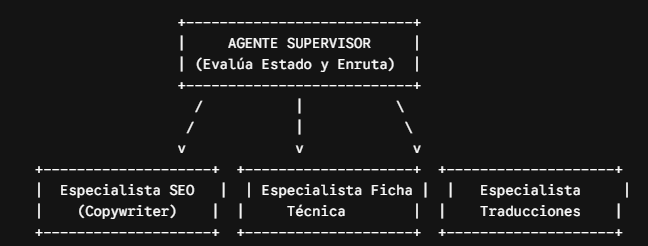

### Principios Fundamentales del Patrón:

1. **Aislamiento de Prompts:** Cada agente especialista cuenta con un `SystemMessage` enfocado exclusivamente en su rol, garantizando máxima precisión.
2. **Estado Global Unificado:** Los especialistas leen del estado compartido de Pydantic y devuelven únicamente el resultado de su especialidad.
3. **Enrutamiento Dinámico Guiado por LLM:** El supervisor examina qué información falta en el producto y decide dinámicamente cuál es el siguiente agente especialista que debe actuar o si el proceso ha finalizado (`FIN`).

In [9]:
import os
from pydantic import BaseModel, Field
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_core.messages import HumanMessage, SystemMessage
from langgraph.graph import StateGraph, START, END

# =====================================================================
# 1. IMPORTACIÓN DE COMPONENTES PREVIOS
# =====================================================================
# Asumimos que estas funciones y clases ya están definidas en tu entorno
# por los módulos anteriores. En un proyecto real harías:
#
# from modulos_anteriores import (
#     inicializar_entorno,
#     EstadoCatalogo,
#     nodo_generar_copywriting
# )


# =====================================================================
# 2. EXTENSIÓN DEL ESTADO MEDIANTE HERENCIA (DRY Principle)
# =====================================================================

class EstadoCuraduria(EstadoCatalogo):
    # Hereda sku, titulo_raw, descripcion_raw, url_imagen, titulo_optimizado, etc.
    # Solo agregamos los campos exclusivos de este flujo multi-agente
    especificaciones_tecnicas: str | None = Field(default=None)
    siguiente_paso: str | None = Field(default=None)


class DecisionSupervisor(BaseModel):
    # Restringimos las opciones del LLM usando los nombres exactos de los nodos
    siguiente: str = Field(
        description="Opciones estrictas: 'nodo_generar_copywriting', 'nodo_tecnico', 'FIN'"
    )


# =====================================================================
# 3. NODOS NUEVOS: SUPERVISOR Y ESPECIALISTA TÉCNICO
# =====================================================================

def nodo_supervisor(estado: EstadoCuraduria) -> dict[str, str]:
    print("\n  [Supervisor]: Inspeccionando avance de curaduría...")
    llm = ChatGoogleGenerativeAI(model="gemini-3.5-flash-lite") #, temperature=0)
    supervisor_estructurado = llm.with_structured_output(DecisionSupervisor)

    prompt_sistema = (
        "Eres el Supervisor de Catálogo. Tu tarea es delegar trabajo a los especialistas.\n"
        "REGLAS DE ENRUTAMIENTO:\n"
        "1. Si falta el título o descripción optimizada, responde 'nodo_generar_copywriting'.\n"
        "2. Si el copy está listo pero faltan las especificaciones técnicas, responde 'nodo_tecnico'.\n"
        "3. Si ambos artefactos están generados, responde 'FIN'."
    )

    contexto_actual = (
        f"SKU: {estado.sku}\n"
        f"Copy SEO Generado: {bool(estado.titulo_optimizado and estado.descripcion_optimizada)}\n"
        f"Especificaciones Generadas: {bool(estado.especificaciones_tecnicas)}"
    )

    decision = supervisor_estructurado.invoke([
        SystemMessage(content=prompt_sistema),
        HumanMessage(content=contexto_actual)
    ])

    proximo_nodo = str(decision.siguiente)
    print(f"   -> Decisión: Enrutar a '{proximo_nodo}'")

    return {"siguiente_paso": proximo_nodo}


def nodo_tecnico(estado: EstadoCuraduria) -> dict[str, str]:
    print("  [Especialista Técnico]: Extrayendo ficha de especificaciones...")
    llm = ChatGoogleGenerativeAI(model="gemini-3.5-flash-lite")

    prompt = (
        "Eres un Ingeniero de Datos de Producto.\n"
        f"Detalles del Producto: {estado.descripcion_raw}\n\n"
        "Extrae las especificaciones técnicas y preséntalas en formato de lista con viñetas (- Clave: Valor)."
    )

    respuesta = llm.invoke([HumanMessage(content=prompt)])

    return {"especificaciones_tecnicas": str(respuesta.content).strip()}


# =====================================================================
# 4. ENRUTADOR DINÁMICO
# =====================================================================

def enrutar_desde_supervisor(estado: EstadoCuraduria) -> str:
    # El enrutador simplemente lee la decisión tomada por el LLM en el nodo supervisor
    destino = estado.siguiente_paso
    if destino in ["nodo_generar_copywriting", "nodo_tecnico"]:
        return destino
    return "END"


# =====================================================================
# 5. COMPILACIÓN DE LA ARQUITECTURA MULTI-AGENTE
# =====================================================================

def construir_grafo_multiagente():
    builder = StateGraph(EstadoCuraduria)

    # 1. Agregamos el nodo supervisor
    builder.add_node("nodo_supervisor", nodo_supervisor)

    # 2. Agregamos el nodo reutilizado del Módulo 2 y el nuevo nodo técnico
    builder.add_node("nodo_generar_copywriting", nodo_generar_copywriting)
    builder.add_node("nodo_tecnico", nodo_tecnico)

    # 3. Flujo inicial hacia el supervisor
    builder.add_edge(START, "nodo_supervisor")

    # 4. El supervisor decide a quién llamar
    builder.add_conditional_edges(
        "nodo_supervisor",
        enrutar_desde_supervisor,
        {
            "nodo_generar_copywriting": "nodo_generar_copywriting",
            "nodo_tecnico": "nodo_tecnico",
            "END": END
        }
    )

    # 5. Los especialistas siempre devuelven el control al supervisor al terminar
    builder.add_edge("nodo_generar_copywriting", "nodo_supervisor")
    builder.add_edge("nodo_tecnico", "nodo_supervisor")

    return builder.compile()


# =====================================================================
# 6. EJECUCIÓN
# =====================================================================

if __name__ == "__main__":
    if inicializar_entorno(): # Función reutilizada del Módulo 1/2
        escuadron_curaduria = construir_grafo_multiagente()

        # Instanciamos usando el nuevo estado extendido
        producto_bruto = EstadoCuraduria(
            sku="SKU-AUD-500",
            titulo_raw="audifonos bluetooth inalambricos",
            descripcion_raw="bateria 24 hrs, cancelacion de ruido activa, bluetooth 5.3, peso 210g, carga rapida USB-C",
            atributos_imagen="Color: Negro | Formato: Over-ear" # Dato requerido por el nodo heredado
        )

        print("\n--- INICIANDO PROCESO DE CURADURÍA MULTI-AGENTE ---")
        resultado_final = escuadron_curaduria.invoke(producto_bruto)

        print("\n================ ENTREGABLE FINAL DEL ESCUADRÓN ================")
        print(f" Título SEO:\n {resultado_final['titulo_optimizado']}\n")
        print(f" Descripción Comercial:\n {resultado_final['descripcion_optimizada']}\n")
        print(f" Especificaciones Técnicas:\n {resultado_final['especificaciones_tecnicas']}")
        print("=================================================================")

 Credenciales de Google API configuradas correctamente.

--- INICIANDO PROCESO DE CURADURÍA MULTI-AGENTE ---

  [Supervisor]: Inspeccionando avance de curaduría...
   -> Decisión: Enrutar a 'nodo_generar_copywriting'
 [Nodo Copywriter]: Redactando título y descripción profesional...

  [Supervisor]: Inspeccionando avance de curaduría...
   -> Decisión: Enrutar a 'nodo_tecnico'
  [Especialista Técnico]: Extrayendo ficha de especificaciones...

  [Supervisor]: Inspeccionando avance de curaduría...
   -> Decisión: Enrutar a 'FIN'

================ ENTREGABLE FINAL DEL ESCUADRÓN ================
 Título SEO:
 audifonos bluetooth inalambricos

 Descripción Comercial:
 bateria 24 hrs, cancelacion de ruido activa, bluetooth 5.3, peso 210g, carga rapida USB-C

 Especificaciones Técnicas:
 [{'type': 'text', 'text': 'Como Ingeniero de Datos de Producto, he procesado y estructurado las especificaciones técnicas extraídas del producto:\n\n- Autonomía de la batería: 24 horas\n- Cancelación de ruido

## Seguridad, Privacidad de Marcas y Filtrado de PII/Datos Sensibles en E-commerce

Exponer información sensible (PII - Personally Identifiable Information) de proveedores o publicar marcas de competidores no autorizados en un catálogo público genera graves problemas legales y de reputación. Los textos crudos provistos por terceros suelen incluir números de teléfono ocultos en las descripciones, correos electrónicos de contacto directo o menciones a marcas registradas (ej. "compatible con Apple", "mejor que Nike") que violan las políticas de los marketplaces.

Para mitigar este riesgo, se implementa un **Patrón de Firewall o Middleware de Seguridad** dentro de LangGraph. Este patrón intercepta los datos antes de que lleguen a los agentes generadores de contenido, utilizando un enfoque híbrido:

1. **Reglas Deterministas (Python nativo):** Para bloquear inmediatamente marcas prohibidas mediante listas negras (Blacklists).
2. **Filtros Cognitivos (LLM):** Para identificar y censurar dinámicamente datos personales (teléfonos, correos, nombres) sin alterar el valor comercial de la descripción.

### Implementación del Firewall Híbrido

El siguiente flujo evalúa primero las reglas estrictas de negocio. Si el producto menciona una marca prohibida, se bloquea y se envía a un **Nodo de Cuarentena**. Si supera esta prueba, pasa a un **Nodo Sanitizador** donde un modelo de lenguaje enmascara cualquier dato personal antes de aprobar el texto para el resto del sistema.

In [13]:
import os
import re
from pydantic import BaseModel, Field
from google.colab import userdata
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_core.messages import HumanMessage
from langgraph.graph import StateGraph, START, END

# =====================================================================
# 1. CONFIGURACIÓN DEL ENTORNO
# =====================================================================


# =====================================================================
# 2. DEFINICIÓN DEL ESTADO DE SEGURIDAD (SIN TYPING LEGACY)
# =====================================================================

class EstadoSeguridad(BaseModel):
    sku: str
    texto_proveedor: str

    # Banderas de control de seguridad
    bloqueo_critico: bool = Field(default=False)
    motivos_bloqueo: list[str] = Field(default_factory=list)

    # Artefacto final seguro
    texto_sanitizado: str | None = Field(default=None)

# =====================================================================
# 3. NODOS DE SEGURIDAD (DETERMINISTA Y COGNITIVO)
# =====================================================================

def nodo_filtro_marcas(estado: EstadoSeguridad) -> dict[str, bool | list[str]]:
    # Motor de reglas nativo para validación estricta (Cero tolerancia)
    print(f"\n [Seguridad - Capa 1]: Escaneando marcas prohibidas en SKU {estado.sku}...")

    marcas_prohibidas = ["nike", "apple", "rolex", "samsung"]
    texto_minusculas = estado.texto_proveedor.lower()

    infracciones = [marca for marca in marcas_prohibidas if marca in texto_minusculas]

    if infracciones:
        mensaje_bloqueo = f"Violación de Propiedad Intelectual: Mención no autorizada de {', '.join(infracciones).upper()}"
        print(f"   X ALERTA CRÍTICA: {mensaje_bloqueo}")

        # En Python 3.10+ podemos retornar listas directamente sin importar typing.List
        return {
            "bloqueo_critico": True,
            "motivos_bloqueo": [mensaje_bloqueo]
        }

    print("   ✓ Capa 1 superada: Sin conflictos de marcas.")
    return {"bloqueo_critico": False}


def nodo_sanitizar_pii(estado: EstadoSeguridad) -> dict[str, str]:
    # Filtro cognitivo: El LLM detecta y redacta información personal de forma contextual
    print(" [Seguridad - Capa 2]: Sanitizando PII (Datos Sensibles)...")
    llm = ChatGoogleGenerativeAI(model="gemini-3.5-flash-lite") #, temperature=0)

    prompt = (
        "Eres un Agente de Seguridad de Datos Estricto.\n"
        "Tu única tarea es reescribir el siguiente texto reemplazando cualquier "
        "número de teléfono, correo electrónico, dirección física o nombre de contacto "
        "con la etiqueta [REDACTADO].\n\n"
        "No modifiques las características del producto, solo oculta los datos sensibles.\n"
        "Si no hay datos sensibles, devuelve el texto exactamente igual.\n\n"
        f"TEXTO ORIGINAL: {estado.texto_proveedor}"
    )

    respuesta = llm.invoke([HumanMessage(content=prompt)])
    texto_limpio = str(respuesta.content).strip()

    # Opcional: Capa de respaldo (Fallback) con Regex tradicional de Python
    # por si el modelo omite algún formato estándar de email.
    texto_limpio = re.sub(r'[\w\.-]+@[\w\.-]+\.\w+', '[EMAIL_REDACTADO]', texto_limpio)

    return {"texto_sanitizado": texto_limpio}


def nodo_cuarentena(estado: EstadoSeguridad) -> dict[str, str]:
    # Nodo sumidero para productos que violan políticas críticas
    print(" [Cuarentena]: Aislando producto y notificando al equipo de Compliance...")
    reporte_incidencia = " | ".join(estado.motivos_bloqueo)

    return {
        "texto_sanitizado": f"PRODUCTO EN CUARENTENA REVISIÓN MANUAL REQUERIDA. Causa: {reporte_incidencia}"
    }

# =====================================================================
# 4. ENRUTADOR DEL FIREWALL
# =====================================================================

def enrutador_firewall(estado: EstadoSeguridad) -> str:
    # Bifurcación basada en el resultado de la capa de marcas
    if estado.bloqueo_critico:
        print(" [Enrutador]: Desviando a -> nodo_cuarentena")
        return "nodo_cuarentena"

    print(" [Enrutador]: Avanzando a -> nodo_sanitizar_pii")
    return "nodo_sanitizar_pii"

# =====================================================================
# 5. COMPILACIÓN DEL GRAFO DE SEGURIDAD
# =====================================================================

def construir_firewall_seguridad():
    builder = StateGraph(EstadoSeguridad)

    # Registro de nodos
    builder.add_node("nodo_filtro_marcas", nodo_filtro_marcas)
    builder.add_node("nodo_sanitizar_pii", nodo_sanitizar_pii)
    builder.add_node("nodo_cuarentena", nodo_cuarentena)

    # El flujo siempre ingresa por el filtro más ligero y barato (determinista)
    builder.add_edge(START, "nodo_filtro_marcas")

    # El enrutador decide si aislar o sanitizar
    builder.add_conditional_edges(
        "nodo_filtro_marcas",
        enrutador_firewall,
        {
            "nodo_cuarentena": "nodo_cuarentena",
            "nodo_sanitizar_pii": "nodo_sanitizar_pii"
        }
    )

    # Ambos caminos terminales finalizan el proceso de seguridad
    builder.add_edge("nodo_cuarentena", END)
    builder.add_edge("nodo_sanitizar_pii", END)

    return builder.compile()

# =====================================================================
# 6. CASOS DE PRUEBA
# =====================================================================

if __name__ == "__main__":
    if inicializar_entorno():
        firewall = construir_firewall_seguridad()

        # CASO 1: Producto seguro pero con datos de contacto (PII)
        print("\n--- EVALUANDO CASO 1: PRODUCTO CON PII (Fuga de Datos) ---")
        producto_con_pii = EstadoSeguridad(
            sku="SKU-MOCHILA-01",
            texto_proveedor="Mochila impermeable de 20L. Excelente calidad. Para compras al por mayor contactar a juan.perez@distribuidora.com o llamar al +56912345678. Despacho inmediato."
        )
        res_1 = firewall.invoke(producto_con_pii)
        print(f"\n Resultado Texto:\n {res_1['texto_sanitizado']}")

        # CASO 2: Producto que viola propiedad intelectual
        print("\n--- EVALUANDO CASO 2: PRODUCTO CON MARCA PROHIBIDA ---")
        producto_ilegal = EstadoSeguridad(
            sku="SKU-RELOJ-99",
            texto_proveedor="Reloj inteligente con correas de metal. Diseño idéntico al Apple Watch pero más económico."
        )
        res_2 = firewall.invoke(producto_ilegal)
        print(f"\n Resultado Texto:\n {res_2['texto_sanitizado']}")


--- EVALUANDO CASO 1: PRODUCTO CON PII (Fuga de Datos) ---

 [Seguridad - Capa 1]: Escaneando marcas prohibidas en SKU SKU-MOCHILA-01...
   ✓ Capa 1 superada: Sin conflictos de marcas.
 [Enrutador]: Avanzando a -> nodo_sanitizar_pii
 [Seguridad - Capa 2]: Sanitizando PII (Datos Sensibles)...

 Resultado Texto:
 [{'type': 'text', 'text': 'Mochila impermeable de 20L. Excelente calidad. Para compras al por mayor contactar a [REDACTADO] o llamar al [REDACTADO]. Despacho inmediato.', 'extras': {'signature': 'EmAKXgFpFH0TvEC0Sg3KaTd5wA+SEGCvirPrUYOAUnu0iTRzy20nFLmI6ahWn1wSXd4OmbBJTjR2UN9wb/R9RIfdBdn+CxTcrSBfppu/E5Jlku7d3oF6MILT7CU+/xP7yyA='}}]

--- EVALUANDO CASO 2: PRODUCTO CON MARCA PROHIBIDA ---

 [Seguridad - Capa 1]: Escaneando marcas prohibidas en SKU SKU-RELOJ-99...
   X ALERTA CRÍTICA: Violación de Propiedad Intelectual: Mención no autorizada de APPLE
 [Enrutador]: Desviando a -> nodo_cuarentena
 [Cuarentena]: Aislando producto y notificando al equipo de Compliance...

 Resultado Te

## Bucles de Evaluación (QA Loop) y Mitigación de Alucinaciones en Especificaciones Técnicas

A diferencia del Módulo 3, donde retrocedíamos basándonos en reglas de código fijo (como contar palabras o buscar en listas negras), aquí enfrentamos un problema semántico: las **alucinaciones**. Cuando un LLM redacta especificaciones técnicas, tiende a "rellenar" vacíos de información asumiendo características comunes (ej. asumir que un SmartTV tiene Bluetooth 5.0 aunque el proveedor no lo especifique).

Para solucionar esto, implementamos el patrón **LLM-as-a-Judge (LLM como Juez)**. En esta arquitectura, un modelo actúa como generador y otro modelo (generalmente configurado con temperatura 0) actúa como auditor. El auditor compara el texto generado exclusivamente contra la "Verdad Base" (Ground Truth o Contexto del Fabricante) y, si detecta datos inventados, devuelve el flujo al generador con un feedback exacto para que se corrija.

### Implementación del Juez Cognitivo contra Alucinaciones

En este código, el Juez utiliza *Structured Outputs* (salidas estructuradas de Pydantic) para emitir un veredicto binario y una justificación. Esto garantiza que la decisión de enrutamiento sea determinista, incluso si la evaluación es semántica.

In [15]:
import os
from pydantic import BaseModel, Field
from google.colab import userdata
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_core.messages import HumanMessage, SystemMessage
from langgraph.graph import StateGraph, START, END

# =====================================================================
# 1. CONFIGURACIÓN DEL ENTORNO
# =====================================================================

def inicializar_entorno() -> bool:
    try:
        os.environ["GOOGLE_API_KEY"] = userdata.get('GOOGLE_API_KEY')
        return True
    except Exception as error:
        print(f"X Error al cargar credenciales: {error}")
        return False

# =====================================================================
# 2. DEFINICIÓN DEL ESTADO Y ESQUEMA DE VEREDICTO (PYTHON MODERNO)
# =====================================================================

class EstadoEvaluacionTecnica(BaseModel):
    sku: str
    contexto_fabricante: str  # La Verdad Base (Ground Truth)

    # Artefacto en construcción
    especificaciones_generadas: str | None = Field(default=None)

    # Control del QA Loop cognitivo
    intentos: int = Field(default=0)
    aprobado_por_juez: bool = Field(default=False)
    feedback_juez: str | None = Field(default=None)


class VeredictoJuez(BaseModel):
    # Forzamos al modelo evaluador a responder con esta estructura estricta
    es_preciso: bool = Field(
        description="True si la especificación se basa SOLO en el contexto. False si contiene información inventada o alucinada."
    )
    explicacion_correccion: str | None = Field(
        default=None,
        description="Si es_preciso es False, detalla exactamente qué dato fue inventado para que el generador lo elimine."
    )

# =====================================================================
# 3. NODOS GENERADOR Y EVALUADOR
# =====================================================================

def nodo_generador_tecnico(estado: EstadoEvaluacionTecnica) -> dict[str, str | int]:
    print(f"\n [Generador] Iteración {estado.intentos + 1}: Extrayendo ficha técnica...")
    llm = ChatGoogleGenerativeAI(model="gemini-3.5-flash-lite") #, temperature=0.4)

    prompt = (
        "Eres un extractor de datos técnicos.\n"
        f"Extrae las especificaciones en una lista de viñetas basándote en este texto:\n"
        f"{estado.contexto_fabricante}\n"
    )

    # Si el juez devolvió el texto por alucinaciones, inyectamos el feedback
    if estado.feedback_juez:
        print(f"   -> Aplicando corrección del juez: {estado.feedback_juez}")
        prompt += f"\nCORRECCIÓN OBLIGATORIA: {estado.feedback_juez}\n"

    respuesta = llm.invoke([HumanMessage(content=prompt)])

    return {
        "especificaciones_generadas": str(respuesta.content).strip(),
        "intentos": estado.intentos + 1
    }


def nodo_juez_alucinaciones(estado: EstadoEvaluacionTecnica) -> dict[str, bool | str | None]:
    print(" [Juez Cognitivo]: Comparando resultado contra la Verdad Base...")
    # El juez siempre debe tener temperatura 0 para ser analítico e inflexible
    llm = ChatGoogleGenerativeAI(model="gemini-3.5-flash-lite") #, temperature=0)
    juez_estructurado = llm.with_structured_output(VeredictoJuez)

    prompt_sistema = (
        "Eres un Auditor de Calidad Técnico. Tu trabajo es detectar alucinaciones.\n"
        "Compara las Especificaciones Generadas contra el Texto del Fabricante.\n"
        "REGLA DE ORO: Si el texto generado menciona características, materiales, conexiones "
        "o números que NO están explícitamente en el texto del fabricante, debes marcar 'es_preciso' como False."
    )

    contexto = (
        f"--- TEXTO DEL FABRICANTE (VERDAD BASE) ---\n{estado.contexto_fabricante}\n\n"
        f"--- ESPECIFICACIONES GENERADAS ---\n{estado.especificaciones_generadas}"
    )

    veredicto = juez_estructurado.invoke([
        SystemMessage(content=prompt_sistema),
        HumanMessage(content=contexto)
    ])

    if veredicto.es_preciso:
        print("   ✓ Veredicto: Preciso. No se detectaron alucinaciones.")
        return {
            "aprobado_por_juez": True,
            "feedback_juez": None
        }
    else:
        print(f"   X Veredicto: Alucinación detectada. Motivo: {veredicto.explicacion_correccion}")
        return {
            "aprobado_por_juez": False,
            "feedback_juez": veredicto.explicacion_correccion
        }

# =====================================================================
# 4. ENRUTADOR DEL BUCLE DE EVALUACIÓN
# =====================================================================

def enrutador_qa_loop(estado: EstadoEvaluacionTecnica) -> str:
    # Si el juez aprueba el contenido, terminamos
    if estado.aprobado_por_juez:
        print(" [Enrutador]: QA Superado -> END")
        return "END"

    # Cortocircuito de seguridad para evitar consumo infinito de API
    if estado.intentos >= 3:
        print(" [Enrutador]: Límite de iteraciones alcanzado. Se requiere revisión humana -> END")
        return "END"

    # Si falló pero quedan intentos, retroceder al generador
    print(" [Enrutador]: Alucinación encontrada, devolviendo a -> nodo_generador_tecnico")
    return "nodo_generador_tecnico"

# =====================================================================
# 5. COMPILACIÓN DEL GRAFO COGNITIVO
# =====================================================================

def construir_grafo_mitigacion():
    builder = StateGraph(EstadoEvaluacionTecnica)

    builder.add_node("nodo_generador_tecnico", nodo_generador_tecnico)
    builder.add_node("nodo_juez_alucinaciones", nodo_juez_alucinaciones)

    builder.add_edge(START, "nodo_generador_tecnico")
    builder.add_edge("nodo_generador_tecnico", "nodo_juez_alucinaciones")

    builder.add_conditional_edges(
        "nodo_juez_alucinaciones",
        enrutador_qa_loop,
        {
            "nodo_generador_tecnico": "nodo_generador_tecnico",
            "END": END
        }
    )

    return builder.compile()

# =====================================================================
# 6. SIMULACIÓN DE ALUCINACIÓN Y CORRECCIÓN
# =====================================================================

if __name__ == "__main__":
    if inicializar_entorno():
        grafo_qa = construir_grafo_mitigacion()

        # Le daremos al sistema un texto muy pobre para "tentar" al generador
        # a inventar características que un SmartTV normalmente tendría.
        producto_trampa = EstadoEvaluacionTecnica(
            sku="SKU-TV-001",
            contexto_fabricante="Televisor LED de 50 pulgadas. Resolución 4K. Incluye control remoto."
            # Nota: NO menciona ni Wi-Fi, ni SmartTV, ni Bluetooth, ni HDMI.
        )

        print("\n--- INICIANDO QA LOOP COGNITIVO ---")
        # Invocamos el grafo. Si el LLM asume características extra, el juez lo atrapará
        # y forzará una segunda iteración.
        resultado = grafo_qa.invoke(producto_trampa)

        print("\n================ ESPECIFICACIONES FINALES VALIDADAS ================")
        print(f" Intentos de generación: {resultado['intentos']}")
        print(f" Aprobado sin alucinaciones: {resultado['aprobado_por_juez']}")
        print(f" Resultado:\n{resultado['especificaciones_generadas']}")
        print("======================================================================")


--- INICIANDO QA LOOP COGNITIVO ---

 [Generador] Iteración 1: Extrayendo ficha técnica...
 [Juez Cognitivo]: Comparando resultado contra la Verdad Base...
   ✓ Veredicto: Preciso. No se detectaron alucinaciones.
 [Enrutador]: QA Superado -> END

================ ESPECIFICACIONES FINALES VALIDADAS ================
 Intentos de generación: 1
 Aprobado sin alucinaciones: True
 Resultado:
[{'type': 'text', 'text': 'Aquí tienes las especificaciones técnicas extraídas:\n\n* Tipo de dispositivo: Televisor LED\n* Tamaño de pantalla: 50 pulgadas\n* Resolución: 4K\n* Accesorios incluidos: Control remoto', 'extras': {'signature': 'EmAKXgFpFH0ThS4Yy+7KLRAsT98qECcu1Kv/yAF5RxePvcqA2ftCBFtkUs/rfJ4UoY7KNRIqESMpAX9hgsS8dyuWPMlSo59hsSFOV7Da/mLsYdp8gu9ppFDLf4T+AhnC1Fo='}}]


# Observabilidad, Trazabilidad Local y Control de Costos en Generación Masiva de Contenido

## Telemetría y Gestión Presupuestaria en Grafos de Estado

Cuando se automatiza el enriquecimiento de miles de fichas de producto para un e-commerce, el costo operacional y la latencia pueden salirse de control rápidamente. A diferencia del software tradicional determinista —donde un error de código arroja una excepción con un código de estado HTTP 500—, los sistemas agénticos stocásticos sufren de **fallas silenciosas**:

- **Ciclos de retroalimentación infinitos:** Agentes atrapados en bucles de corrección que consumen cientos de miles de tokens antes de finalizar.
- **Degradación de rendimiento:** Prompts excesivamente extensos o acumulación innecesaria de contexto que disparan los tiempos de respuesta a decenas de segundos por producto.
- **Costos ocultos:** Falta de visibilidad sobre cuántos tokens de entrada (prompts) y salida (generación) consume cada especialista dentro del catálogo.

Para construir un pipeline agéntico apto para producción masiva, es indispensable implementar tres capas de observabilidad:

1. **Manejo de Callbacks Locales (Custom Callbacks):** Interceptar cada evento de inferencia directamente en memoria para registrar latencia, tokens y respuestas en archivos de log locales sin enviar telemetría a plataformas de terceros.
2. **Contabilidad de Tokens y Estimación de Costos:** Calcular en tiempo real el gasto presupuestario acumulado por cada producto procesado en el estado.
3. **Mecanismo de Interrupción / Cortocircuito Financiero:** Detener la ejecución si un producto supera el umbral máximo de presupuesto asignado antes de continuar consumiendo APIs.

In [20]:
import os
import time
from pydantic import BaseModel, Field
from google.colab import userdata
from langchain_core.callbacks import BaseCallbackHandler
from langchain_core.messages import HumanMessage
from langchain_google_genai import ChatGoogleGenerativeAI
from langgraph.graph import StateGraph, START, END


# =====================================================================
# 1. CONFIGURACIÓN DEL ENTORNO DE TRABAJO
# =====================================================================

def inicializar_entorno() -> bool:
    # Carga la clave de API desde los secretos del entorno Colab
    try:
        os.environ["GOOGLE_API_KEY"] = userdata.get('GOOGLE_API_KEY')
        print(" Credenciales de Google API configuradas correctamente.")
        return True
    except Exception as error:
        print(f"X Error al cargar credenciales: {error}")
        return False


# =====================================================================
# 2. MODELADO DEL ESTADO CON CONTROL FINANCIERO (SIN MÓDULO TYPING)
# =====================================================================

class EstadoObservabilidad(BaseModel):
    # Identificador y datos de entrada del producto
    sku: str
    titulo_raw: str
    descripcion_raw: str

    # Métricas de telemetría acumuladas
    tokens_prompt: int = Field(default=0)
    tokens_generacion: int = Field(default=0)
    costo_estimado_usd: float = Field(default=0.0)
    tiempo_ejecucion_segundos: float = Field(default=0.0)

    # Umbral de presupuesto estricto por SKU (Caso Crítico: $0.00005 USD)
    presupuesto_maximo_usd: float = Field(default=0.00005)
    exceso_presupuesto: bool = Field(default=False)

    # Resultado del procesamiento
    ficha_optimizada: str | None = Field(default=None)


# =====================================================================
# 3. INTERCEPTOR LOCAL DE TELEMETRÍA (LOCAL TRACING CALLBACK)
# =====================================================================

class GestorTelemetriaLocal(BaseCallbackHandler):
    """
    Interceptor de eventos que mide el tiempo de respuesta del modelo
    y registra las invocaciones a la API localmente.
    """
    def __init__(self) -> None:
        self.inicio_tiempo: float = 0.0
        self.tiempo_total: float = 0.0

    def on_llm_start(self, serialized: dict[str, str], prompts: list[str], **kwargs) -> None:
        # Captura el tiempo inicial justo antes de iniciar la inferencia
        self.inicio_tiempo = time.time()
        print("   [Callback Local]: Enviando solicitud de inferencia al LLM...")

    def on_llm_end(self, response, **kwargs) -> None:
        # Calcula la latencia total de la llamada
        self.tiempo_total = time.time() - self.inicio_tiempo
        print(f"   [Callback Local]: Respuesta recibida en {self.tiempo_total:.2f} segundos.")


# =====================================================================
# 4. NODOS CON EXTRACCIÓN DE METADATOS Y CONTROL DE COSTOS
# =====================================================================

def nodo_copywriting_monitoreado(estado: EstadoObservabilidad) -> dict[str, str | int | float | bool]:
    print(f"\n [Nodo Monitoreado]: Procesando SKU {estado.sku}...")

    # Instanciamos el callback para medir latencia
    handler_local = GestorTelemetriaLocal()
    llm = ChatGoogleGenerativeAI(
        model="gemini-3.5-flash-lite",
        callbacks=[handler_local]
    )

    prompt = (
        "Eres un experto en Copywriting para E-commerce.\n"
        f"Crea un título optimizado y una descripción persuasiva para:\n"
        f"Producto: {estado.titulo_raw}\n"
        f"Detalles: {estado.descripcion_raw}"
    )

    respuesta = llm.invoke([HumanMessage(content=prompt)])

    # Extraemos métricas de tokens directamente desde la respuesta de LangChain (usage_metadata)
    tokens_input = 0
    tokens_output = 0

    if hasattr(respuesta, 'usage_metadata') and respuesta.usage_metadata:
        tokens_input = respuesta.usage_metadata.get("input_tokens", 0)
        tokens_output = respuesta.usage_metadata.get("output_tokens", 0)

    # Respaldo de cálculo en caso de que el proveedor no retorne metadatos en memoria
    if tokens_input == 0:
        tokens_input = len(prompt.split()) * 2
    if tokens_output == 0:
        tokens_output = len(str(respuesta.content).split()) * 2

    # Tarifas de cálculo para Gemini Flash Lite (USD por token):
    # Input: $0.075 / 1,000,000 tokens | Output: $0.30 / 1,000,000 tokens
    costo_input = (tokens_input / 1_000_000) * 0.075
    costo_output = (tokens_output / 1_000_000) * 0.30
    costo_total_llamada = costo_input + costo_output

    # Actualización acumulativa del costo en el estado
    costo_acumulado = estado.costo_estimado_usd + costo_total_llamada
    supero_presupuesto = costo_acumulado > estado.presupuesto_maximo_usd

    print(f"   [Telemetría]: Tokens Input = {tokens_input} | Tokens Output = {tokens_output}")
    print(f"   [Telemetría]: Costo de la llamada = ${costo_total_llamada:.6f} USD")

    # Sintaxis limpia sin barras invertidas innecesarias
    if supero_presupuesto:
        print(f"   ⚠️ ALERTA DE COSTO ACTIVADA: ({costo_acumulado:.6f} USD supera el límite de {estado.presupuesto_maximo_usd:.6f} USD)")

    return {
        "ficha_optimizada": str(respuesta.content).strip(),
        "tokens_prompt": estado.tokens_prompt + tokens_input,
        "tokens_generacion": estado.tokens_generacion + tokens_output,
        "costo_estimado_usd": costo_acumulado,
        "tiempo_ejecucion_segundos": estado.tiempo_ejecucion_segundos + handler_local.tiempo_total,
        "exceso_presupuesto": supero_presupuesto
    }


def nodo_cortocircuito_costos(estado: EstadoObservabilidad) -> dict[str, str]:
    # Nodo de emergencia que bloquea el flujo si se supera el presupuesto
    print(f"\n [Cortocircuito Financiero]: CANCELANDO PASOS SUBSIGUIENTES PARA SKU {estado.sku}.")
    mensaje_alerta = (
        f"PROCESAMIENTO BLOQUEADO: El costo acumulado (${estado.costo_estimado_usd:.6f} USD) "
        f"superó el presupuesto máximo permitido (${estado.presupuesto_maximo_usd:.6f} USD)."
    )
    return {"ficha_optimizada": mensaje_alerta}


# =====================================================================
# 5. ENRUTADOR CONDICIONAL PRESUPUESTARIO
# =====================================================================

def evaluar_cortocircuito_financiero(estado: EstadoObservabilidad) -> str:
    # Si la bandera de exceso de presupuesto está encendida, desviamos al cortocircuito
    if estado.exceso_presupuesto:
        print(" [Enrutador]: Exceso de costo detectado -> Redirigiendo a nodo_cortocircuito_costos")
        return "nodo_cortocircuito_costos"

    print(" [Enrutador]: Presupuesto dentro del límite -> Finalizando flujo en END")
    return "END"


# =====================================================================
# 6. COMPILACIÓN DEL GRAFO DE OBSERVABILIDAD
# =====================================================================

def construir_grafo_observabilidad():
    builder = StateGraph(EstadoObservabilidad)

    # Registrar nodos operacionales
    builder.add_node("nodo_copywriting_monitoreado", nodo_copywriting_monitoreado)
    builder.add_node("nodo_cortocircuito_costos", nodo_cortocircuito_costos)

    # Flujo de inicio
    builder.add_edge(START, "nodo_copywriting_monitoreado")

    # Arista condicional de control financiero
    builder.add_conditional_edges(
        "nodo_copywriting_monitoreado",
        evaluar_cortocircuito_financiero,
        {
            "nodo_cortocircuito_costos": "nodo_cortocircuito_costos",
            "END": END
        }
    )

    builder.add_edge("nodo_cortocircuito_costos", END)

    return builder.compile()


# =====================================================================
# 7. EJECUCIÓN Y SALIDA DEL CASO CRÍTICO
# =====================================================================

if __name__ == "__main__":
    if inicializar_entorno():
        grafo_monitoreado = construir_grafo_observabilidad()

        # Presupuesto restrictivo para activar la alerta sin SyntaxWarning
        producto_caso_critico = EstadoObservabilidad(
            sku="SKU-CRITICO-999",
            titulo_raw="Silla de Escritorio Ergonómica Reclinable",
            descripcion_raw="Silla con soporte lumbar ajustable, apoyabrazos 3D, malla respirable y rueda de silicona de alta resistencia para oficina.",
            presupuesto_maximo_usd=0.00001
        )

        print("\n--- INICIANDO PROCESAMIENTO CON PRESUPUESTO RESTRICTIVO ---")
        resultado = grafo_monitoreado.invoke(producto_caso_critico)

        print("\n================ REPORTAJE DE OBSERVABILIDAD Y TELEMETRÍA ================")
        print(f" SKU Procesado: {resultado['sku']}")
        print(f" Tiempo Total de Inferencia: {resultado['tiempo_ejecucion_segundos']:.2f} segundos")
        print(f" Tokens de Entrada (Prompt): {resultado['tokens_prompt']}")
        print(f" Tokens de Salida (Generación): {resultado['tokens_generacion']}")
        print(f" Costo Total Calculado: ${resultado['costo_estimado_usd']:.6f} USD")
        print(f" Alerta Presupuestaria Activada: {resultado['exceso_presupuesto']}")
        print(f" Estado Final de la Ficha:\n {resultado['ficha_optimizada']}")
        print("=========================================================================")

 Credenciales de Google API configuradas correctamente.

--- INICIANDO PROCESAMIENTO CON PRESUPUESTO RESTRICTIVO ---

 [Nodo Monitoreado]: Procesando SKU SKU-CRITICO-999...
   [Callback Local]: Enviando solicitud de inferencia al LLM...
   [Callback Local]: Respuesta recibida en 3.72 segundos.
   [Telemetría]: Tokens Input = 73 | Tokens Output = 660
   [Telemetría]: Costo de la llamada = $0.000203 USD
   ⚠️ ALERTA DE COSTO ACTIVADA: (0.000203 USD supera el límite de 0.000010 USD)
 [Enrutador]: Exceso de costo detectado -> Redirigiendo a nodo_cortocircuito_costos

 [Cortocircuito Financiero]: CANCELANDO PASOS SUBSIGUIENTES PARA SKU SKU-CRITICO-999.

================ REPORTAJE DE OBSERVABILIDAD Y TELEMETRÍA ================
 SKU Procesado: SKU-CRITICO-999
 Tiempo Total de Inferencia: 3.72 segundos
 Tokens de Entrada (Prompt): 73
 Tokens de Salida (Generación): 660
 Costo Total Calculado: $0.000203 USD
 Alerta Presupuestaria Activada: True
 Estado Final de la Ficha:
 PROCESAMIENTO BLOQUEA

# Persistencia de Estado, Checkpoints y Control del Tiempo (Time-Travel) en Modificación de Productos

## Auditoría, Reversión de Cambios y Memoria Persistente en Catálogos

En entornos de comercio electrónico en producción, la edición de un catálogo no es un evento aislado. Los gerentes de producto (Category Managers) constantemente modifican descripciones, corrigen precios o revierten descripciones generadas por IA que no tuvieron el impacto comercial esperado.

Si ejecutamos un agente sin **mecanismo de persistencia**, el estado vive únicamente en la memoria RAM durante la ejecución de la función. Tan pronto como el flujo llega a `END`, el historial de transformaciones desaparece.

### Los 3 Conceptos Clave de la Persistencia en LangGraph:

1. **Checkpointers (Guardadores de Estado):** Componentes como `MemorySaver` (en desarrollo/RAM) o `PostgresSaver` (en producción/Base de Datos) que guardan una foto instantánea (*snapshot*) del estado exacto del producto en cada paso del grafo.
2. **Hilos de Ejecución (`thread_id`):** Un identificador único (por ejemplo, el SKU o el ID de la sesión del usuario) que aísla la memoria de cada producto. Permite que miles de usuarios o procesos modifiquen catálogos simultáneamente sin mezclar datos.
3. **Control del Tiempo (Time-Travel / State Rewind):** Capacidad de inspeccionar el historial completo de Checkpoints de un producto, retroceder a una versión previa en la historia de edición y bifurcar el flujo para probar una nueva descripción sin perder la trazabilidad.

## Implementación Práctica: Historial, Checkpoints y Reversión de Cambios

In [22]:
import os
from pydantic import BaseModel, Field
from google.colab import userdata
from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_core.messages import HumanMessage
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import MemorySaver


# =====================================================================
# 1. CONFIGURACIÓN DE CREDENCIALES
# =====================================================================

def inicializar_entorno() -> bool:
    try:
        os.environ["GOOGLE_API_KEY"] = userdata.get('GOOGLE_API_KEY')
        print(" Credenciales de Google API configuradas correctamente.")
        return True
    except Exception as error:
        print(f"X Error al cargar credenciales: {error}")
        return False


# =====================================================================
# 2. FUNCIÓN AUXILIAR DE EXTRACCIÓN DE TEXTO LIMPIO
# =====================================================================

def extraer_texto_limpio(contenido_raw: str | list | dict) -> str:
    """
    Saca el texto plano limpio de la respuesta de Gemini sin importar
    si viene como string o como lista de bloques con metadatos.
    """
    if isinstance(contenido_raw, str):
        return contenido_raw.strip()
    if isinstance(contenido_raw, list):
        textos = []
        for elemento in contenido_raw:
            if isinstance(elemento, dict) and "text" in elemento:
                textos.append(elemento["text"])
            elif isinstance(elemento, str):
                textos.append(elemento)
        return "\n".join(textos).strip()
    return str(contenido_raw).strip()


# =====================================================================
# 3. ESTADO DEL PRODUCTO CON SEGUIMIENTO DE VERSIONES
# =====================================================================

class EstadoPersistente(BaseModel):
    sku: str
    titulo: str
    descripcion_raw: str

    # Campo incremental para auditar los cambios hechos por el agente
    version_catalogo: int = Field(default=1)
    historial_versiones: list[str] = Field(default_factory=list)


# =====================================================================
# 4. NODOS DE TRANSFORMACIÓN DE CATÁLOGO
# =====================================================================

def nodo_optimizar_titulo(estado: EstadoPersistente) -> dict[str, str | int | list[str]]:
    print(f"\n [Paso 1 - Titulación]: Optimizando título para versión {estado.version_catalogo}...")
    llm = ChatGoogleGenerativeAI(model="gemini-3.5-flash-lite")

    # Exigimos explícitamente UN solo título sin listas ni alternativas
    prompt = (
        f"Escribe ÚNICAMENTE UN título comercial para e-commerce (máximo 8 palabras) "
        f"basado en este producto: {estado.titulo}. "
        f"No des opciones, no uses viñetas, no expliques nada. Solo responde con el título final."
    )
    respuesta = llm.invoke([HumanMessage(content=prompt)])

    # Extracción de texto limpio eliminando bloques de metadatos de Gemini
    nuevo_titulo = extraer_texto_limpio(respuesta.content)
    registro = f"v{estado.version_catalogo}: Título actualizado a '{nuevo_titulo}'"

    return {
        "titulo": nuevo_titulo,
        "version_catalogo": estado.version_catalogo + 1,
        "historial_versiones": estado.historial_versiones + [registro]
    }


def nodo_enriquecer_descripcion(estado: EstadoPersistente) -> dict[str, str | int | list[str]]:
    print(f" [Paso 2 - Copywriting]: Redactando descripción persuasiva para versión {estado.version_catalogo}...")
    llm = ChatGoogleGenerativeAI(model="gemini-3.5-flash-lite")

    prompt = (
        f"Escribe ÚNICAMENTE una descripción comercial de 2 oraciones para el producto "
        f"'{estado.titulo}' con detalles: {estado.descripcion_raw}."
    )
    respuesta = llm.invoke([HumanMessage(content=prompt)])

    nueva_desc = extraer_texto_limpio(respuesta.content)
    registro = f"v{estado.version_catalogo}: Descripción enriquecida por IA"

    return {
        "descripcion_raw": nueva_desc,
        "version_catalogo": estado.version_catalogo + 1,
        "historial_versiones": estado.historial_versiones + [registro]
    }


# =====================================================================
# 5. COMPILACIÓN DEL GRAFO CON CHECKPOINTER (MEMORY SAVER)
# =====================================================================

def construir_grafo_persistente():
    builder = StateGraph(EstadoPersistente)

    builder.add_node("nodo_optimizar_titulo", nodo_optimizar_titulo)
    builder.add_node("nodo_enriquecer_descripcion", nodo_enriquecer_descripcion)

    builder.add_edge(START, "nodo_optimizar_titulo")
    builder.add_edge("nodo_optimizar_titulo", "nodo_enriquecer_descripcion")
    builder.add_edge("nodo_enriquecer_descripcion", END)

    # Checkpointer en memoria para persistencia de estados
    checkpointer_memoria = MemorySaver()

    return builder.compile(checkpointer=checkpointer_memoria)


# =====================================================================
# 6. EJECUCIÓN Y PRUEBA DE TIME-TRAVEL
# =====================================================================

if __name__ == "__main__":
    if inicializar_entorno():
        grafo_persistente = construir_grafo_persistente()

        # Identificador de hilo único por producto
        configuracion_hilo = {"configurable": {"thread_id": "SKU-CALZADO-2026"}}

        producto_inicial = EstadoPersistente(
            sku="SKU-CALZADO-2026",
            titulo="zapatilla running hombre",
            descripcion_raw="zapatilla para correr 10k amortiguacion ligera"
        )

        print("\n--- 1. PRIMERA EJECUCIÓN (Generación de Checkpoints) ---")
        resultado_inicial = grafo_persistente.invoke(producto_inicial, config=configuracion_hilo)

        print("\n================ ESTADO FINAL DE LA SESIÓN ================")
        print(f" Título Final: {resultado_inicial['titulo']}")
        print(f" Descripción Final: {resultado_inicial['descripcion_raw']}")
        print(f" Versión del Producto: v{resultado_inicial['version_catalogo']}")
        print(" Historial de Cambios Registrados:")
        for log in resultado_inicial['historial_versiones']:
            print(f"   • {log}")

        print("\n--- 2. INSPECCIÓN DE LA MEMORIA PERSISTENTE (Snapshot Inspection) ---")
        estado_guardado = grafo_persistente.get_state(configuracion_hilo)
        print(f" Estado actual guardado en el hilo 'SKU-CALZADO-2026':")
        print(f"   • ID del Checkpoint actual: {estado_guardado.config['configurable']['checkpoint_id']}")

        print("\n--- 3. REVISIÓN HISTÓRICA DE CHECKPOINTS (Time-Travel Trail) ---")
        historial_estados = list(grafo_persistente.get_state_history(configuracion_hilo))
        print(f" Total de snapshots de estado en la base de datos: {len(historial_estados)}")

        for i, snapshot in enumerate(reversed(historial_estados), 1):
            datos_snapshot = snapshot.values
            print(f"   Snapshot {i} | Versión: {datos_snapshot.get('version_catalogo', 1)} | Título: '{datos_snapshot.get('titulo')}'")

 Credenciales de Google API configuradas correctamente.

--- 1. PRIMERA EJECUCIÓN (Generación de Checkpoints) ---

 [Paso 1 - Titulación]: Optimizando título para versión 1...
 [Paso 2 - Copywriting]: Redactando descripción persuasiva para versión 2...

================ ESTADO FINAL DE LA SESIÓN ================
 Título Final: Zapatillas de Running para Hombre de Alto Rendimiento
 Descripción Final: Domina tus carreras de 10K con estas zapatillas de running para hombre de alto rendimiento, diseñadas para ofrecerte una amortiguación ligera en cada kilómetro. Experimenta la máxima comodidad y velocidad sin peso extra, alcanzando tus metas con la tecnología más avanzada en tus pies.
 Versión del Producto: v3
 Historial de Cambios Registrados:
   • v1: Título actualizado a 'Zapatillas de Running para Hombre de Alto Rendimiento'
   • v2: Descripción enriquecida por IA

--- 2. INSPECCIÓN DE LA MEMORIA PERSISTENTE (Snapshot Inspection) ---
 Estado actual guardado en el hilo 'SKU-CALZADO-2026'

# Despliegue de Producción Escalable con FastAPI, Streaming y LangGraph Persistente

Para llevar un agente al mundo real y procesar miles de solicitudes (ej. integrarlo a un front-end de e-commerce o a un panel de administración), los scripts locales no son suficientes. Debemos empaquetar el grafo en un **microservicio asíncrono**.

En esta arquitectura de nivel empresarial, integraremos:

1. **FastAPI:** Como capa de red (API REST) para recibir peticiones concurrentes.
2. **Streaming Server-Sent Events (SSE):** Para transmitir los cambios de estado nodo por nodo hacia el cliente en tiempo real (vital para UX y evitar *timeouts*).
3. **Persistencia (Checkpointers):** Para mantener la memoria de la conversación o el historial del producto.
4. **Integración Externa (RAG y Nube):** Nodos especializados que simulan conexiones a una Base de Datos Vectorial (ej. Pinecone, Vertex AI Search) y a servicios Cloud (ej. Google BigQuery / Cloud Storage).

## Arquitectura de Producción (Cloud Run / GKE)

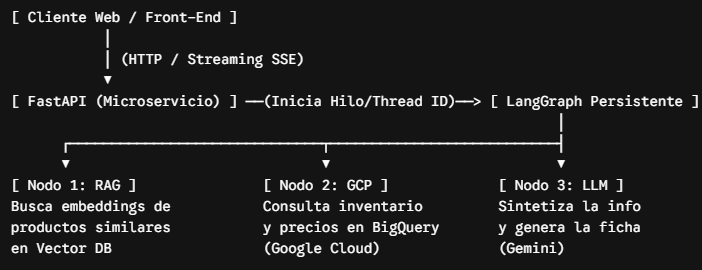

## Implementación de la API de Producción (`app.py`)

El siguiente código está diseñado para ejecutarse como un servidor real. En un entorno de producción, cambiaríamos el `MemorySaver` por un `AsyncPostgresSaver` de LangGraph para guardar el estado en una base de datos relacional.

In [26]:
!pip install nest_asyncio

/usr/lib/python3.13/pathlib/_local.py:274: RuntimeWarning: coroutine 'Server.serve' was never awaited
  parsed = [sys.intern(str(x)) for x in rel.split(sep) if x and x != '.']


In [29]:
import os
import json
import asyncio
from typing import AsyncGenerator
from pydantic import BaseModel, Field
from fastapi import FastAPI
from fastapi.responses import StreamingResponse
from fastapi.middleware.cors import CORSMiddleware
import uvicorn

from langchain_google_genai import ChatGoogleGenerativeAI
from langchain_core.messages import HumanMessage
from langgraph.graph import StateGraph, START, END
from langgraph.checkpoint.memory import MemorySaver

# =====================================================================
# 1. MODELOS DE DATOS (FASTAPI Pydantic + LangGraph State)
# =====================================================================

# Modelo para recibir la petición HTTP POST
class PeticionProducto(BaseModel):
    sku: str
    consulta_usuario: str
    thread_id: str

# Modelo de Estado del Grafo
class EstadoProduccion(BaseModel):
    sku: str
    consulta_usuario: str
    contexto_vectorial: str = Field(default="")
    datos_inventario_gcp: str = Field(default="")
    respuesta_final: str = Field(default="")
    paso_actual: str = Field(default="Iniciando")

# =====================================================================
# 2. HERRAMIENTAS Y CONEXIONES (SIMULADAS)
# =====================================================================

async def buscar_en_vector_db(sku: str, consulta: str) -> str:
    """Simula una búsqueda por similitud semántica en Pinecone o Vertex AI Vector Search."""
    await asyncio.sleep(0.5) # Simula latencia de red
    return f"Documentos similares encontrados en VectorDB para {sku}. Tendencia actual: 'Diseño minimalista'."

async def consultar_bigquery_gcp(sku: str) -> str:
    """Simula una consulta SQL a Google BigQuery para obtener stock y precio en tiempo real."""
    await asyncio.sleep(0.6) # Simula latencia de base de datos
    return f"Stock: 150 unidades en almacén central. Precio actual: $45.99 USD."

# =====================================================================
# 3. NODOS DEL GRAFO ASÍNCRONO
# =====================================================================

async def nodo_recuperacion_vectorial(estado: EstadoProduccion) -> dict:
    contexto = await buscar_en_vector_db(estado.sku, estado.consulta_usuario)
    return {
        "contexto_vectorial": contexto,
        "paso_actual": "Recuperación RAG completada"
    }

async def nodo_integracion_gcp(estado: EstadoProduccion) -> dict:
    datos_gcp = await consultar_bigquery_gcp(estado.sku)
    return {
        "datos_inventario_gcp": datos_gcp,
        "paso_actual": "Consulta a GCP completada"
    }

async def nodo_generacion_llm(estado: EstadoProduccion) -> dict:
    # Se recomienda usar credenciales por entorno (ej. os.environ["GOOGLE_API_KEY"])
    llm = ChatGoogleGenerativeAI(model="gemini-3.5-flash-lite")

    prompt = (
        f"Eres un asistente de e-commerce. Responde a la consulta: '{estado.consulta_usuario}'.\n"
        f"Producto SKU: {estado.sku}\n"
        f"Contexto de tendencias (VectorDB): {estado.contexto_vectorial}\n"
        f"Datos comerciales (GCP BigQuery): {estado.datos_inventario_gcp}\n"
        f"Genera una respuesta breve, estructurada y persuasiva."
    )

    respuesta = await llm.ainvoke([HumanMessage(content=prompt)])

    # Manejo de compatibilidad para extraer el texto limpio
    texto_final = str(respuesta.content)
    if isinstance(respuesta.content, list):
        texto_final = " ".join([b["text"] for b in respuesta.content if "text" in b])

    return {
        "respuesta_final": texto_final,
        "paso_actual": "Generación completada"
    }

# =====================================================================
# 4. COMPILACIÓN DEL GRAFO
# =====================================================================

def crear_grafo_produccion():
    builder = StateGraph(EstadoProduccion)

    builder.add_node("RAG_Vectorial", nodo_recuperacion_vectorial)
    builder.add_node("API_GCP", nodo_integracion_gcp)
    builder.add_node("Generacion_LLM", nodo_generacion_llm)

    # Ejecución paralela simulada (LangGraph ejecutará ambos secuencialmente en este setup simple,
    # pero preparan el contexto para el LLM)
    builder.add_edge(START, "RAG_Vectorial")
    builder.add_edge("RAG_Vectorial", "API_GCP")
    builder.add_edge("API_GCP", "Generacion_LLM")
    builder.add_edge("Generacion_LLM", END)

    memoria_produccion = MemorySaver()
    return builder.compile(checkpointer=memoria_produccion)

grafo_app = crear_grafo_produccion()

# =====================================================================
# 5. CONFIGURACIÓN DE FASTAPI Y STREAMING
# =====================================================================

app = FastAPI(title="Agente E-commerce Masivo API", version="1.0.0")

# Permite que frontends externos (React, Vue) consuman la API
app.add_middleware(
    CORSMiddleware,
    allow_origins=["*"],
    allow_methods=["*"],
    allow_headers=["*"],
)

async def generador_streaming_grafo(peticion: PeticionProducto) -> AsyncGenerator[str, None]:
    """
    Ejecuta el grafo de forma asíncrona y emite (yield) cada cambio de estado nodo por nodo.
    Esto permite que el cliente vea el progreso en la UI ("Buscando...", "Consultando stock...").
    """
    estado_inicial = EstadoProduccion(
        sku=peticion.sku,
        consulta_usuario=peticion.consulta_usuario
    )

    config = {"configurable": {"thread_id": peticion.thread_id}}

    # astream() itera sobre los eventos del grafo a medida que los nodos finalizan
    async for evento in grafo_app.astream(estado_inicial, config=config):
        # 'evento' es un diccionario con la salida del nodo que acaba de ejecutarse
        for nombre_nodo, estado_actualizado in evento.items():

            # Formateamos como Server-Sent Event (SSE)
            payload = {
                "nodo": nombre_nodo,
                "paso": estado_actualizado.get("paso_actual", ""),
                "datos_parciales": estado_actualizado.get("respuesta_final", "")
            }

            yield f"data: {json.dumps(payload)}\n\n"

    yield "data: [DONE]\n\n"

@app.post("/agente/stream")
async def endpoint_streaming_agente(peticion: PeticionProducto):
    """
    Endpoint que devuelve un flujo de datos (Stream) en lugar de esperar
    a que todo el proceso termine. Fundamental para mitigar latencia en producción.
    """
    return StreamingResponse(
        generador_streaming_grafo(peticion),
        media_type="text/event-stream"
    )

@app.get("/agente/memoria/{thread_id}")
async def inspeccionar_estado(thread_id: str):
    """Permite auditar el estado actual guardado en el checkpointer para un cliente/producto."""
    config = {"configurable": {"thread_id": thread_id}}
    snapshot = grafo_app.get_state(config)
    if snapshot and snapshot.values:
        return {"thread_id": thread_id, "estado": snapshot.values}
    return {"error": "Hilo no encontrado o sin datos."}

# =====================================================================
# 6. PRUEBA DE PRODUCCIÓN: CONSUMO DE STREAMING DIRECTO (PARA COLAB)
# =====================================================================

async def probar_agente_streaming():
    print("Iniciando solicitud asíncrona al Agente de Producción...\n")

    # 1. Simulamos el payload (cuerpo JSON) que enviaría un frontend (React/Vue)
    peticion_prueba = PeticionProducto(
        sku="SKU-PRO-777",
        consulta_usuario="¿Tienen stock de este producto y cuál es la tendencia de diseño?",
        thread_id="sesion-cliente-frontend-01"
    )

    # 2. Consumimos el stream de eventos en tiempo real
    print("--- CONSOLA DEL CLIENTE FRONTEND (Recibiendo datos) ---")
    async for evento_sse in generador_streaming_grafo(peticion_prueba):
        # Imprimimos cada "paquete" de datos justo en el milisegundo que el nodo lo emite
        print(evento_sse.strip())
        print("-" * 50)

    print("\n[Operación finalizada. Conexión cerrada.]")

# En Jupyter/Colab podemos usar 'await' directamente en la raíz de la celda
# sin necesidad de asyncio.run()
await probar_agente_streaming()

Iniciando solicitud asíncrona al Agente de Producción...

--- CONSOLA DEL CLIENTE FRONTEND (Recibiendo datos) ---
data: {"nodo": "RAG_Vectorial", "paso": "Recuperaci\u00f3n RAG completada", "datos_parciales": ""}
--------------------------------------------------
data: {"nodo": "API_GCP", "paso": "Consulta a GCP completada", "datos_parciales": ""}
--------------------------------------------------


data: {"nodo": "Generacion_LLM", "paso": "Generaci\u00f3n completada", "datos_parciales": "\u00a1Hola! Con gusto te comparto la informaci\u00f3n sobre el producto **SKU-PRO-777**:\n\n*   **Disponibilidad:** \u00a1S\u00ed tenemos stock! Contamos con **150 unidades** listas para env\u00edo inmediato en nuestro almac\u00e9n central.\n*   **Precio:** $45.99 USD.\n*   **Tendencia de dise\u00f1o:** Este producto destaca por su **dise\u00f1o minimalista**, una de las tendencias m\u00e1s buscadas actualmente por su elegancia, versatilidad y capacidad de adaptarse a cualquier espacio o estilo.\n\nEs una excelente opci\u00f3n y se est\u00e1 vendiendo muy r\u00e1pido. \u00bfTe gustar\u00eda agregarlo a tu carrito ahora?"}
--------------------------------------------------
data: [DONE]
--------------------------------------------------

[Operación finalizada. Conexión cerrada.]


ecommerce_langgraph_project/
├── app/                              # Código fuente principal de la aplicación
│   ├── api/                          # Capa de red y exposición (Módulo 10)
│   │   ├── __init__.py
│   │   ├── endpoints.py              # Rutas POST /agente, GET /memoria
│   │   ├── streaming.py              # Generadores de Server-Sent Events (SSE)
│   │   └── middlewares.py            # CORS, Rate Limiting, Autenticación
│   │
│   ├── core/                         # Configuraciones y modelos base (Módulo 2)
│   │   ├── __init__.py
│   │   ├── config.py                 # Variables de entorno (Pydantic BaseSettings)
│   │   └── state_models.py           # Esquemas Pydantic del estado del catálogo
│   │
│   ├── graphs/                       # Lógica central del orquestador (Módulos 1, 3, 7)
│   │   ├── __init__.py
│   │   ├── builder.py                # Compilación del StateGraph y sub-grafos
│   │   ├── nodes.py                  # Funciones de transformación de texto
│   │   ├── edges.py                  # Enrutamiento condicional y flujos cíclicos
│   │   └── qa_loops.py               # Nodos de validación y "LLM-como-Juez"
│   │
│   ├── agents/                       # Patrones multi-agente (Módulo 5)
│   │   ├── __init__.py
│   │   ├── supervisor.py             # Agente orquestador delegador
│   │   ├── seo_agent.py              # Sub-agente especialista en posicionamiento
│   │   └── copywriter_agent.py       # Sub-agente especialista en redacción
│   │
│   ├── tools/                        # Integraciones y contexto externo (Módulo 4)
│   │   ├── __init__.py
│   │   ├── rag_vector_db.py          # Conexión a Pinecone / Vertex AI Search
│   │   ├── vision_parser.py          # Análisis multimodal de imágenes
│   │   └── gcp_connectors.py         # Clientes para BigQuery / Cloud Storage
│   │
│   ├── security/                     # Gobernanza y protección corporativa (Módulo 6)
│   │   ├── __init__.py
│   │   ├── pii_filters.py            # Sanitización de datos sensibles
│   │   └── brand_guardrails.py       # Bloqueo de menciones a la competencia
│   │
│   ├── observability/                # Telemetría y control financiero (Módulo 8)
│   │   ├── __init__.py
│   │   ├── callbacks.py              # Interceptores de latencia y uso
│   │   └── cost_tracker.py            # Cortocircuitos y auditoría de tokens
│   │
│   ├── memory/                       # Persistencia de estado (Módulo 9)
│   │   ├── __init__.py
│   │   ├── checkpointers.py          # Configuración de AsyncPostgresSaver
│   │   └── time_travel.py            # Utilidades para revertir versiones (snapshots)
│   │
│   └── main.py                       # Punto de entrada de la aplicación FastAPI
│
├── tests/                            # Pruebas automatizadas (Unitarias y de Integración)
│   ├── test_graphs.py                # Pruebas de transiciones de estado
│   ├── test_guardrails.py            # Pruebas de filtros de seguridad
│   └── test_api_streaming.py         # Pruebas de endpoints SSE
│
├── infra/                            # Infraestructura como Código (IaC) y Despliegue
│   ├── Dockerfile                    # Receta de contenerización del microservicio
│   ├── docker-compose.yml            # Entorno local (FastAPI, PostgreSQL, Redis)
│   └── cloud_run_deploy.sh           # Script de despliegue a Google Cloud Run
│
├── .env.example                      # Plantilla de variables de entorno (API Keys, DB URIs)
├── .gitignore
├── pyproject.toml                    # Dependencias modernas (Poetry o UV)
└── README.md                         # Documentación de arquitectura y ejecución